# Computer Vision I · Assignment 1 · guided notebook

**Computer Vision I · MIA 2026/27 · Statement of 05 Nov 2026 · Deadline 17 Nov 2026 · Presentation in class 18 Nov 2026 · Groups of 2**

**The goal of this notebook:** when you reach the end, the assignment is done. You will have written the two mathematical answers (exercises 1 and 2), every function exercises 3 to 6 need, every figure the report needs, and the comments the statement asks for. Nothing in here is the solution: every proof, every line of assignment logic and every comment is yours.

**The notebook is the source of truth.** Your code does not live in loose cells. Each part has one cell that starts with `%%writefile a1_<something>.py`: running that cell *writes* a small Python module next to this notebook, and the rest of the notebook imports it. You only ever edit the code here, never in the `.py` file, so the two can never disagree. Part 0.3 explains how this works with a toy module.

Each part follows the same rhythm:

1. 📖 **Read before you start this part**: the book sections to read first, with an estimated time and what to look for.
2. **Theory, with 🧭 Think steps inside it.** The theory explains the concepts and the tools, but it deliberately stops *before* the conclusions you need. Those you reach yourself through short 🧭 **Think** questions placed between its paragraphs: each one can be answered from what you have just read (or just run), and the next paragraph builds on your answer. Write each answer in the `Answer here` cell below it before reading on.
3. ▶️ **Worked examples**: small runnable examples of each *tool* you need, deliberately in **another context** (another kernel, another reduction, another kind of data). They show how a function is called and what it returns. They are never your task with other numbers, so copying one will not give you the answer: you have to understand it and decide how it applies. *What to notice* names the concept, never "do this in your task".
4. ❓ **Questions**: at the end of each theory block, one or two bigger questions that put the 🧭 steps together, applied to the assignment.
5. ✍️ **Your task**: what you write next. For code you get the **contract** (name, arguments, what it returns, what it must guarantee) as a signature and docstring, and a list of requirements, not a list of lines to type. The body is a placeholder, `raise NotImplementedError`, that you replace. For the maths you get the structure of the answer, the blanks are yours.
6. ✅ **Test**: a cell that checks your functions on toy data. Run it before moving on. Its error messages point to the 🧭 step to revisit.
7. 🛠️ **Use it**: where you run your functions on *your* photo, save the figures for the report and write the comments.

| Part | Statement | Points | What you produce | Your module |
| --- | --- | --- | --- | --- |
| 0 | — | — | Environment on Windows and Mac, folders, how modules are written | — |
| 1 | Ex. 1: rigid transformations preserve distances and angles | 3 | The proof | — |
| 2 | Ex. 2: $^{A}_{B}R$ for rotations about $\mathbf{i}_A$ and $\mathbf{j}_A$ | 2 | The derivation | — |
| 3 | Ex. 3: photo, resize to 448×336, read and show with OpenCV | 3 | Your scene, loaded and shown | `a1_image.py` |
| 4 | Ex. 4: Gabor filter at 4 orientations, max combination, 3 parameter sets | 4 | Filter bank + figures | `a1_gabor.py` |
| 5 | Ex. 5: Canny, compared with Gabor | 4 | Edge maps + comparison | `a1_canny.py` |
| 6 | Ex. 6: Gaussian and Laplacian pyramids, comment on frequencies | 4 | Both pyramids + comment | `a1_pyramids.py` |

The points add up to 20. The assignment counts for about 20 % of the course grade ([Lecture 1](<../../Slides/Lecture 1.pdf>), p. 4; the teacher said it might end up 15 %).

**Book abbreviations**

- **Sz** = R. Szeliski, *Computer Vision: Algorithms and Applications*, 2nd ed., Springer, 2022. **Your copy:** [books/Szeliski (2022)…pdf](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf>) (also free online at [szeliski.org/Book](https://szeliski.org/Book/)). The teacher recommended it first. Every Sz reference in this notebook is a link that opens the PDF at the right page (PDF page = book page + 26).
- **F&P** = D. Forsyth and J. Ponce, *Computer Vision: A Modern Approach*, 2nd ed., Pearson, 2012. Exercises 1 and 2 of the statement come from its Chapter 1 and use its notation. **Not in your folder and no free copy:** where a box cites F&P and Sz, the Sz link covers the same topic.
- **Prince** = S. Prince, *Computer Vision: Models, Learning, and Inference*, Cambridge UP, 2012 ([computervisionmodels.com](http://www.computervisionmodels.com/)).
- **L1** = the course slides *Lecture 1 – Introduction*, [Slides/Lecture 1.pdf](<../../Slides/Lecture 1.pdf>) (PDF page numbers). The second deck is [Slides/Lecture 2.pdf](<../../Slides/Lecture 2.pdf>).

All Sz section numbers and pages were checked against your PDF (14/11). Chapter and section titles of F&P were checked against the publisher's table of contents.

> ⚠️ **Generative-AI rule of the course** ([L1](<../../Slides/Lecture 1.pdf>), pp. 8–11). You may use GenAI only for minor things (structure, specific answers, summaries, literature pointers, style), you must **declare** it in the report, and you must **document how you verified** its output. Text or code that you did not largely write yourself, or major ideas, are not allowed, and a violation means a zero. This notebook is GenAI help: declare it. Every line you write in the `raise NotImplementedError` and `Answer here` cells must be yours, and both members of the group must be able to defend it on 18 Nov.
>
> **Collaboration** ([L1](<../../Slides/Lecture 1.pdf>), p. 7): discussing with other students is allowed, but write down with whom. Duplicate or substantially similar submissions get a zero.

---
# Part 0 — Setup on Windows and macOS (VS Code)

> 📖 **Read before you start this part** (10 min)
> - The statement once more: note which exercises are maths (1, 2), which are code (3 to 6), and what the report must contain.
> - [opencv-python on PyPI](https://pypi.org/project/opencv-python/), the section on the four package flavours. The point to retain: install **one** of them only.

### Why a virtual environment, and why outside OneDrive?

A **virtual environment** (venv) is a private folder with its own Python and its own packages. OpenCV and NumPy go there instead of into your system Python, so they cannot clash with other courses (your NLU or ML environments), and deleting the folder removes everything.

Put the venv **outside** OneDrive. A venv holds thousands of small files: OneDrive would try to upload all of them, can lock a file in the middle of `pip install`, and a venv is tied to one machine and one Python anyway (a Windows venv does not run on a Mac). The notebook and your modules stay in the OneDrive folder, the venv lives in your home folder. You already have a `.venvs` folder in your Windows home, so we use the same name on both systems: `~/.venvs/cv1`.

### Which OpenCV?

`pip install opencv-python` gives the main modules with GUI support (`cv2.imshow` needs it). Do **not** also install `opencv-contrib-python` or a `-headless` flavour in the same venv: all four install the same `cv2` package and overwrite each other, and the headless ones have no `imshow` at all. Since July 2026 the newest release is OpenCV **5.0**. Every function this assignment uses (`imread`, `resize`, `imshow`, `getGaborKernel`, `filter2D`, `Canny`, `pyrDown`, `pyrUp`, `GaussianBlur`) exists with the same signature in 4.x, so the lab computers (probably 4.x) and your laptop will behave the same. The examples here were run with OpenCV 5.0.0, NumPy 2.5 and Matplotlib 3.11.

<details>
<summary><b>Step by step: build the environment (click to open)</b></summary>

### Step 1 — Check which Python you have

**Windows (PowerShell):**
```powershell
py --list          # the Python launcher lists the installed versions
```
If `py` is not found, install Python 3.12 or 3.13 from python.org (tick *Add python.exe to PATH*), then reopen PowerShell.

**macOS (Terminal):**
```bash
python3 --version
```
Any 3.10 to 3.13 is fine. On 3.14 the OpenCV wheel installs too (it is an `abi3` wheel, built for 3.7 and later), but some other package may still lack a 3.14 build, so 3.12 or 3.13 is the safe choice (`brew install python@3.12`).

### Step 2 — Create the venv and install the four packages

We never *activate* the venv: we call its own Python by its full path. This avoids PowerShell's execution-policy error on `Activate.ps1`, and it is impossible to install into the wrong Python by accident.

**Windows (PowerShell):**
```powershell
py -3.12 -m venv $HOME\.venvs\cv1
& $HOME\.venvs\cv1\Scripts\python.exe -m pip install --upgrade pip
& $HOME\.venvs\cv1\Scripts\python.exe -m pip install opencv-python numpy matplotlib ipykernel
& $HOME\.venvs\cv1\Scripts\python.exe -c "import cv2, numpy; print(cv2.__version__, numpy.__version__)"
```

**macOS (Terminal):**
```bash
python3 -m venv ~/.venvs/cv1
~/.venvs/cv1/bin/python -m pip install --upgrade pip
~/.venvs/cv1/bin/python -m pip install opencv-python numpy matplotlib ipykernel
~/.venvs/cv1/bin/python -c "import cv2, numpy; print(cv2.__version__, numpy.__version__)"
```

| Piece | What it does |
| --- | --- |
| `py -3.12 -m venv <folder>` / `python3 -m venv <folder>` | `-m venv` runs Python's built-in venv module, which creates the folder with a copy of that Python. |
| `& <path>\python.exe ...` | In PowerShell, `&` means "run the program at this path". On macOS you just type the path. |
| `-m pip install --upgrade pip` | Updates pip, the package installer, *inside the venv*. `python -m pip` guarantees you use the pip of that Python. |
| `opencv-python numpy matplotlib` | OpenCV (`cv2`), arrays, and plots. NumPy is installed by OpenCV anyway, but naming it documents the dependency. |
| `ipykernel` | Lets VS Code run notebooks with this Python. |
| `-c "import ..."` | Runs one line of Python to prove the install works. |

### Step 3 — Open the notebook in VS Code with the venv

1. Install the **Python** and **Jupyter** extensions (Microsoft) from the Extensions panel.
2. **File → Open Folder…** and choose the `Assignment 1` folder (the one that contains this notebook).
3. Top right of the notebook: **Select Kernel → Python Environments → `cv1`**. If it is not listed: `Ctrl+Shift+P` (Windows) or `Cmd+Shift+P` (Mac) → *Python: Select Interpreter* → *Enter interpreter path* → `C:\Users\<you>\.venvs\cv1\Scripts\python.exe` (Windows) or `~/.venvs/cv1/bin/python` (Mac). Then select the kernel again.
4. Run the next cell. It only uses the standard library, so it runs even when OpenCV is missing, and tells you what is wrong.

</details>

In [1]:
import sys, platform, importlib.util
from importlib import metadata

print("Python     :", sys.version.split()[0], "|", platform.system(), platform.machine())
print("Executable :", sys.executable)
for name in ["cv2", "numpy", "matplotlib"]:
    print(f"{name:11s}:", "found" if importlib.util.find_spec(name) else "MISSING -> pip install (Part 0, Step 2)")

installed = []
for dist in ["opencv-python", "opencv-contrib-python", "opencv-python-headless", "opencv-contrib-python-headless"]:
    try:
        installed.append(f"{dist} {metadata.version(dist)}")
    except metadata.PackageNotFoundError:
        pass
print("OpenCV dist:", installed if installed else "none")
if len(installed) > 1:
    print("⚠️ More than one OpenCV package: uninstall all of them and install only opencv-python.")

Python     : 3.14.10 | Windows AMD64
Executable : d:\Python\pymanager\pythoncore-3.14-64\python.exe
cv2        : found
numpy      : found
matplotlib : found
OpenCV dist: ['opencv-python 5.0.0.93']


**What to notice:** `sys.executable` is the Python that runs this notebook. It should end in `.venvs\cv1\Scripts\python.exe` (Windows) or `.venvs/cv1/bin/python` (Mac). If it does not, VS Code is using another Python, which is the usual cause of `ModuleNotFoundError: No module named 'cv2'` after a successful install.

### 0.2 — Imports, folders and the switch for OpenCV windows

The next cell is the setup cell of the whole notebook. Run it every time you open the notebook.

- `pathlib.Path` builds paths that work on Windows (`\`) and macOS (`/`): `DATA_DIR / "scene.jpg"` is correct on both. Never write `"data\\scene.jpg"` or `"data/scene.jpg"` by hand.
- VS Code runs a notebook from the notebook's own folder, so `Path(".")` is the `Assignment 1` folder. The cell prints it: check it.
- `data/` holds your photo, `figures/` holds every figure of the report. The cell creates both.
- `USE_CV_WINDOWS` controls the cells that open a native OpenCV window (`cv2.imshow`). Leave it `True`. Set it to `False` only if a window freezes your kernel (Part 3 explains why that can happen).
- `%load_ext autoreload` and `%autoreload 2` are explained in 0.3.

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import math
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

WORK_DIR = Path(".").resolve()
DATA_DIR = WORK_DIR / "data"
FIG_DIR = WORK_DIR / "figures"
HELPERS_DIR = WORK_DIR / "helpers"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
HELPERS_DIR.mkdir(exist_ok=True)

import sys
sys.path.insert(0, str(HELPERS_DIR))     # Python now looks in helpers/ first when you import

USE_CV_WINDOWS = True          # False = never call cv2.imshow (see Part 3)

np.set_printoptions(precision=4, suppress=True)
print("Notebook folder:", WORK_DIR)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

Notebook folder: C:\Users\wargu\OneDrive\Claude OS\MIA\Computer Vision I\Assignments\Assignment 1
OpenCV 5.0.0 | NumPy 2.4.6 | Matplotlib 3.11.2


---
## 0.3 — How this notebook writes your modules

### Theory

A **module** is a `.py` file. `import a1_gabor` makes Python look for `a1_gabor.py` in the current folder (and then in the installed packages), run it once, and give you a name, `a1_gabor`, through which you reach its functions: `a1_gabor.gabor_bank(...)`. Why bother, instead of writing functions in cells?

- The report asks for *code snippets (main lines of code)*. Short, named functions in one file per exercise are exactly that: you copy the main lines of `a1_gabor.py` into the report.
- A module has no hidden state. A cell-defined function can silently use a variable from a cell you ran an hour ago. A module only sees what it imports or receives as an argument, so if the tests pass, they pass for the right reason.
- You and your partner can open the same `.py` files on Windows and Mac.

**`%%writefile name.py`** is an IPython *cell magic*: it must be the first line of the cell, and running the cell does **not** execute the code below it. It writes the cell's text to `name.py` (overwriting the file) and prints `Writing name.py` or `Overwriting name.py`. Consequences:

1. A syntax error in the cell is not reported when you run it. It shows up at the next `import` or test.
2. After you change the cell, you must **run it again**, otherwise the `.py` file on disk still holds the old version.
3. You edit only the cell, never the `.py` in an editor: the next run of the cell would overwrite your edit.

**`%autoreload 2`** tells IPython to check, before every cell, whether an imported module's file changed on disk, and to reload it. Without it, Python imports a module once per kernel session and keeps the old version in memory, even after you rewrite the file. With it, the loop is: edit the `%%writefile` cell → run it → run the test cell. If something ever looks stale, **Restart** the kernel and run the setup cell: that always works.

Two traps:

- **Do not shadow a library.** A file called `cv2.py`, `numpy.py` or `math.py` next to the notebook would be imported *instead of* the real library. That is why every module here starts with `a1_`.
- **A module needs its own imports.** A notebook shares imports between cells, a module does not: `a1_gabor.py` must start with `import numpy as np` and `import cv2` itself.

### ▶️ Example 0.1 — A toy module written, imported, edited

**What this example shows:** the full cycle on a module that has nothing to do with the assignment.

In [3]:
%%writefile helpers/toy_shapes.py
import math

def circle_area(radius):
    """Area of a circle of the given radius."""
    return math.pi * radius ** 2

Overwriting helpers/toy_shapes.py


In [4]:
import toy_shapes
print(toy_shapes.circle_area(1.0))
print("defined in:", toy_shapes.__file__)

3.141592653589793
defined in: C:\Users\wargu\OneDrive\Claude OS\MIA\Computer Vision I\Assignments\Assignment 1\helpers\toy_shapes.py


Now change the return line of the `%%writefile` cell above to `return round(math.pi * radius ** 2, 2)`, run that cell again (it prints `Overwriting toy_shapes.py`), and run the `import` cell again: the result changes without restarting, thanks to `%autoreload 2`.

**What to notice:** `import toy_shapes` worked because the `.py` file sits next to the notebook, which is the folder Python searches first. In every part of this assignment you will do exactly this: one `%%writefile a1_xxx.py` cell with your functions, then tests that `import a1_xxx as alias`. The toy file is not needed afterwards and you can delete it.

---
# Part 1 — Exercise 1: rigid transformations preserve distances and angles (3 points)

> *Statement.* Show that the change of coordinates associated with a rigid transformation preserves distances and angles.
> *Hint 1:* use 3 points and check that after the transformation angles and distances are the same.
> *Hint 2:* $|AB|^2 = \mathrm{tr}(B^T A^T A B)$, where $A$ and $B$ are vectors or matrices.

> 📖 **Read before you start this part** (45 min)
> - **F&P §1.2.1** *Rigid Transformations and Homogeneous Coordinates*. Look for: the notation ${}^{F}P$, ${}^{A}O_B$, ${}^{A}_{B}R$, the change-of-coordinates formula, and what is said about the columns of a rotation matrix. This exercise is one of the chapter's exercises, in the chapter's notation.
> - **[Sz §2.1, p. 36](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=62>)** *Geometric primitives and transformations*, the 3D transformations and 3D rotations subsections ([§2.1.2, p. 43](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=69>) and [§2.1.3, p. 45](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=71>)). Look for: the table of transformations and the column "preserves".
> - Any linear-algebra summary of: the transpose of a product, the trace $\mathrm{tr}(M) = \sum_i M_{ii}$, and the dot product written as $\mathbf{u}^T\mathbf{v}$.

## Theory, step by step

### 1. Why this matters, and the change of coordinates

A camera measures the world in its own frame, a robot or a room in another. Before trusting a length or an angle measured in the camera frame, you need to know that changing frame does not distort it. That is what this exercise proves.

A **frame** $(A)$ is an origin $O_A$ and three unit vectors $\mathbf{i}_A, \mathbf{j}_A, \mathbf{k}_A$, mutually perpendicular. A point $P$ is a place in space. Its **coordinates** ${}^{A}P \in \mathbb{R}^3$ depend on the frame. F&P write the relation between the coordinates of the same point in two frames as

$$
{}^{B}P \;=\; {}^{B}_{A}R\; {}^{A}P \;+\; {}^{B}O_A ,
$$

where ${}^{B}_{A}R$ is a $3\times3$ **rotation matrix** and ${}^{B}O_A$ is the origin of $A$ measured in $B$. Rotation followed by translation is a **rigid** (or *Euclidean*) transformation. Read the indices like a fraction that cancels: the lower-left $A$ of ${}^{B}_{A}R$ "eats" the upper-left $A$ of ${}^{A}P$ and leaves a $B$.

What makes a matrix a rotation matrix (F&P §1.2.1): its three **columns are unit vectors, mutually perpendicular** (they are the axes of one frame written in the other), and its determinant is $+1$. A reflection also has perpendicular unit columns, but determinant $-1$.

Recall how a matrix product works: entry $(i, j)$ of $M^TN$ is the dot product of column $i$ of $M$ with column $j$ of $N$.

### 🧭 Think T1.1
> Use the fact above: entry $(i,j)$ of $R^TR$ is the dot product of column $i$ and column $j$ of $R$. For a rotation matrix, what is that dot product when $i = j$? When $i \neq j$? So what matrix is $R^TR$?

Entry $(i, j)$ of $R^{\mathsf{T}}R$ is the dot product of columns $i$ and $j$ of $R$. The columns of a rotation are orthonormal, so $i = j$ gives 1 and $i \neq j$ gives 0. Therefore $R^{\mathsf{T}}R = I$. Checked on $R(90°) = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$: $R^{\mathsf{T}}R = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}$.

### 2. Points and vectors

A **vector** between two points, $\overrightarrow{PQ}$, has coordinates "end minus start": ${}^{A}\overrightarrow{PQ} = {}^{A}Q - {}^{A}P$. A length or an angle is always a property of vectors between points, never of a single point's coordinates (the coordinates of one point change with the origin, its distance to another point does not).

### 🧭 Think T1.2
> Write the change of coordinates for $P$ and for $Q$ (two lines), and subtract them. Write ${}^{B}\overrightarrow{PQ}$ in terms of ${}^{A}\overrightarrow{PQ}$. What happened to ${}^{B}O_A$? Why does that mean that, from now on, only the rotation can change a length or an angle?

$p' = R\,p + t$ and $q' = R\,q + t$. Subtracting gives $q' - p' = R\,(q - p)$. The same $t$ is added to both points, so it cancels. Only $R$ can still change a length or an angle.

### 3. Lengths and angles are dot products

With $\mathbf{u}$ and $\mathbf{v}$ two vectors (columns),

$$
\|\mathbf{u}\| = \sqrt{\mathbf{u}^T\mathbf{u}}, \qquad
\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}^T\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|}, \quad \text{angle} \in [0, \pi].
$$

### 🧭 Think T1.3
> Look at the two formulas only. Suppose someone proved to you that $\mathbf{u}^T\mathbf{v}$ has the same value in frame $A$ and in frame $B$, for **any** two vectors. Would that be enough to conclude that lengths are the same in both frames? And angles? Why? (So: what is the *one* thing your proof needs to show?)

Lengths and angles are both computed from dot products: $|u| = \sqrt{u^{\mathsf{T}} u}$ and $\cos\theta = \dfrac{u^{\mathsf{T}} v}{|u|\,|v|}$. So it is enough to show that the dot product is the same in both frames: $u'^{\mathsf{T}} v' = u^{\mathsf{T}} v$.

### 4. What the rotation does to a dot product

Call $R = {}^{B}_{A}R$, and let $\mathbf{u}_A, \mathbf{v}_A$ be two vectors in frame $A$, $\mathbf{u}_B, \mathbf{v}_B$ the same vectors in frame $B$. T1.2 told you how $\mathbf{u}_B$ is obtained from $\mathbf{u}_A$. Two facts of linear algebra are all you need: $(MN)^T = N^TM^T$, and matrix products can be regrouped freely ($(MN)K = M(NK)$).

### 🧭 Think T1.4
> (a) Write $\mathbf{u}_B^T$ in terms of $R$ and $\mathbf{u}_A$.
> (b) Write $\mathbf{u}_B^T\mathbf{v}_B$ as one product of four factors, and regroup it so that $R^TR$ appears in the middle.
> (c) Use T1.1. What is left?

(a) $u'^{\mathsf{T}} = (R u)^{\mathsf{T}} = u^{\mathsf{T}} R^{\mathsf{T}}$. (b) $u'^{\mathsf{T}} v' = u^{\mathsf{T}} R^{\mathsf{T}} R\, v$. (c) $R^{\mathsf{T}}R = I$, so $u'^{\mathsf{T}} v' = u^{\mathsf{T}} v$.

### 5. Reading the two hints of the statement

**Hint 2.** For a vector $\mathbf{w}$, $\mathbf{w}^T\mathbf{w}$ is a $1\times1$ matrix, and the **trace** of a $1\times1$ matrix is its only entry. The same expression $\mathrm{tr}(B^TB)$ also makes sense when $B$ is a matrix: it is then the sum of the squares of all its entries (the squared *Frobenius norm*). That is why the statement writes the hint with a trace: it covers vectors and matrices at once.

**Hint 1.** Three points $P$, $Q$, $S$.

### 🧭 Think T1.5
> In $|AB|^2 = \mathrm{tr}(B^TA^TAB)$, which object of T1.4 plays $A$ and which plays $B$ when you compute the squared length of a transformed vector? Which line of T1.4 is this hint, in disguise?

In $|AB|^2 = \mathrm{tr}(B^{\mathsf{T}}A^{\mathsf{T}}AB)$, $A$ is $R$ and $B$ is the vector $u = q - p$. It is T1.4 with $v = u$: $|u'|^2 = u^{\mathsf{T}} R^{\mathsf{T}} R\, u = u^{\mathsf{T}} u$. The trace of a $1\times1$ matrix is its only entry.

### 🧭 Think T1.6
> Why are two points enough for a distance but three needed for an angle? Which angle do $P, Q, S$ define, and from which two vectors? Is a check on three *particular* numerical points a proof? What makes the argument a proof?

Two points give one vector, which is enough for a distance. An angle needs two vectors from the same vertex: $P, Q, S$ give $\overrightarrow{PQ}$ and $\overrightarrow{PS}$, and the angle $QPS$. A check on particular numbers only illustrates the result. The argument is a proof because $P, Q, S, R$ and $t$ are arbitrary.

### ❓ Question Q1.1
> Your argument used $R^TR = I$. Did it use $\det R = +1$? So, does a reflection such as ${\rm diag}(1, 1, -1)$ also preserve distances and the (unsigned) angle between two vectors? What *does* a reflection change that a rotation does not, and why do rigid motions of real objects require $\det = +1$? *(Where to read: F&P §1.2.1 · [Sz §2.1, p. 36](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=62>).)*

The proof only used $R^{\mathsf{T}}R = I$, not $\det R = +1$. A reflection such as $\mathrm{diag}(1, 1, -1)$ also has orthonormal columns, so it also keeps distances and unsigned angles, but it mirrors the object. A real object cannot be turned into its mirror image by moving it, so rigid motions need $\det R = +1$. Also, $\det = 1$ alone does not protect lengths: the shear $\begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$ has $\det = 1$ but turns $(0, 1)$ into $(1, 1)$.

### ▶️ Example 1.1 — Writing maths in a markdown cell

**What this example shows:** the LaTeX you need for exercises 1 and 2, on an unrelated identity. Double-click this cell to see the source.

Inline maths goes between single dollars: the frame $(A)$, the point ${}^{A}P$, the matrix ${}^{A}_{B}R$, the vector $\overrightarrow{PQ}$, $\mathbf{u}^T\mathbf{v}$, $\theta$.

A displayed chain of equalities uses `aligned`, `&` before each `=`, `\\` at the end of each line, and `&& \text{...}` for a justification on the right:

$$
\begin{aligned}
(a+b)^2 &= (a+b)(a+b) && \text{(definition of the square)} \\
        &= a^2 + ab + ba + b^2 && \text{(distributivity)} \\
        &= a^2 + 2ab + b^2 && \text{(commutativity)}.
\end{aligned}
$$

A matrix: $M = \begin{pmatrix} m_{11} & m_{12} \\ m_{21} & m_{22} \end{pmatrix}$.

**What to notice:** `{}^{A}_{B}R` (an empty group `{}` before the superscript) puts both indices on the **left**, as F&P writes them. Word's equation editor (Alt + =) and Google Docs accept most of this syntax when you move the answer into the report.

## ✍️ Your task 1a — the proof (in the cell below, then in the report)

You have every piece: T1.1 (orthogonality), T1.2 (vectors), T1.3 (strategy), T1.4 (the computation), T1.5 (Hint 2), T1.6 (Hint 1). Now write them as one proof, in your words, in this order:

1. **Setting.** Two frames, the change of coordinates in F&P's notation, the property of ${}^{B}_{A}R$ you will use.
2. **Three points** $P, Q, S$, arbitrary, and the two vectors from $P$, in both frames.
3. **Distances**, through Hint 2.
4. **Dot products**, the same computation for two different vectors.
5. **Angles**, from 3 and 4.
6. **Conclusion** in one sentence, including what Q1.1 taught you.

Justify each equality to its right (Example 1.1). It should fit in about half a page of the report.

**Proof.**

**Notation.** A point $P$ has coordinates $p$ in the old frame and $p'$ in the new frame. A rigid change of coordinates is a rotation $R$ followed by a translation $t$:
$$
p' = R\,p + t .
$$
Following Hint 1, we take three arbitrary points $P$, $Q$ and $S$.

**Step 1 — The key property of a rotation: $R^{\mathsf{T}} R = I$.** The columns of $R$ are the axes of the new frame written in the old one, so they are unit vectors and mutually perpendicular (orthonormal). Entry $(i, j)$ of $R^{\mathsf{T}} R$ is the dot product of column $i$ and column $j$ of $R$. It equals 1 when $i = j$ (a unit vector with itself) and 0 when $i \neq j$ (two perpendicular vectors). Therefore $R^{\mathsf{T}} R = I$. For example, for a rotation of $90°$ in the plane,
$$
R = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}, \qquad
R^{\mathsf{T}} = \begin{pmatrix} 0 & 1 \\ -1 & 0 \end{pmatrix}, \qquad
R^{\mathsf{T}} R = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}.
$$

**Step 2 — The translation cancels.** Distances and angles are measured on vectors between points, not on single points. Let $u = q - p$ and $v = s - p$ be the two vectors leaving $P$. In the new frame,
$$
u' = q' - p' = (R\,q + t) - (R\,p + t) = R\,(q - p) = R\,u ,
$$
and in the same way $v' = R\,v$. The same $t$ is added to both points and disappears in the subtraction. For example, with the $90°$ rotation and $t = (5, 5)$, the points $p = (1, 0)$ and $q = (3, 0)$ become $p' = (5, 6)$ and $q' = (5, 8)$: every coordinate changes, but $q' - p' = (0, 2) = R\,(2, 0)$ and the distance is 2 in both frames. Only $R$ can still affect lengths and angles.

**Step 3 — What must be shown.** Lengths and angles are both computed from dot products:
$$
|u| = \sqrt{u^{\mathsf{T}} u}, \qquad \cos\theta = \frac{u^{\mathsf{T}} v}{|u|\,|v|} .
$$
So we need to check that $R$ changes neither the length of a vector nor the dot product of two vectors.

**Step 4 — Distances (Hint 2).** Using $(Ru)^{\mathsf{T}} = u^{\mathsf{T}} R^{\mathsf{T}}$ and Step 1, the length of a vector does not change:
$$
|u'|^2 = (R\,u)^{\mathsf{T}} (R\,u) = u^{\mathsf{T}} (R^{\mathsf{T}} R)\, u = u^{\mathsf{T}} u = |u|^2 .
$$
This is Hint 2, $|AB|^2 = \operatorname{tr}(B^{\mathsf{T}} A^{\mathsf{T}} A B)$, with $A = R$ and $B = u$ (the trace of a $1\times1$ matrix is its only entry). Since lengths are non-negative, $|PQ|' = |PQ|$, and likewise $|PS|' = |PS|$.

**Step 5 — Dot products.** The same computation with two different vectors:
$$
u'^{\mathsf{T}} v' = (R\,u)^{\mathsf{T}} (R\,v) = u^{\mathsf{T}} (R^{\mathsf{T}} R)\, v = u^{\mathsf{T}} v .
$$

**Step 6 — Angles.** The angle $\theta$ between $PQ$ and $PS$ satisfies
$$
\cos\theta' = \frac{u'^{\mathsf{T}} v'}{|u'|\,|v'|} = \frac{u^{\mathsf{T}} v}{|u|\,|v|} = \cos\theta ,
$$
and since $\theta$ lies in $[0, \pi]$, $\theta' = \theta$.

**Conclusion.** $P$, $Q$ and $S$ were arbitrary, so the change of coordinates associated with a rigid transformation preserves every distance and every angle.

---
# Part 2 — Exercise 2: the matrices ${}^{A}_{B}R$ for rotations about $\mathbf{i}_A$ and $\mathbf{j}_A$ (2 points)

> *Statement.* Derive the formulas for the matrices ${}^{A}_{B}R$ when $(B)$ is deduced from $(A)$ via a rotation of angle $\theta$ about the axes $\mathbf{i}_A$ (x-axis) and $\mathbf{j}_A$ (y-axis) respectively.

> 📖 **Read before you start this part** (30 min)
> - **F&P §1.2.1** again: the part where ${}^{A}_{B}R$ is written in terms of the axes of the two frames, and the worked case of a rotation about $\mathbf{k}_A$ (with its figure). Your two answers use the same reasoning on the other two axes.
> - **[Sz §2.1, p. 36](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=62>)** 3D rotations ([§2.1.3, p. 45](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=71>)): the right-hand rule. Sz uses another notation. Write your answer in the simple notation agreed in `A1_Workbook.md` (x, y, z and x′, y′, z′).

## Theory, step by step

### 1. What the columns of ${}^{A}_{B}R$ are

By Part 1, ${}^{A}_{B}R$ turns the $B$-coordinates of any vector into its $A$-coordinates: ${}^{A}\mathbf{w} = {}^{A}_{B}R\;{}^{B}\mathbf{w}$. Apply this to the axes of $B$ themselves.

### 🧭 Think T2.1
> What are the coordinates of the vector $\mathbf{i}_B$ in its own frame $B$, that is ${}^{B}\mathbf{i}_B$? Knowing that a matrix times $(1,0,0)^T$ gives its first column, what is ${}^{A}_{B}R\;{}^{B}\mathbf{i}_B$? So what is the first column of ${}^{A}_{B}R$, in words? The second and third?

In its own frame, $\mathbf{i}_B = (1, 0, 0)$. Multiplying ${}^{A}_{B}R$ by $(1, 0, 0)$ gives its first column. So column 1 is $\mathbf{i}_B$ written in $A$, column 2 is $\mathbf{j}_B$ and column 3 is $\mathbf{k}_B$: the columns are where the axes land.

### 2. Coordinates of a unit vector are dot products

The coordinates of a vector $\mathbf{w}$ in frame $A$ are its projections on the three axes: $(\mathbf{i}_A\cdot\mathbf{w},\ \mathbf{j}_A\cdot\mathbf{w},\ \mathbf{k}_A\cdot\mathbf{w})$. For two **unit** vectors, the dot product is the cosine of the angle between them.

### 🧭 Think T2.2
> Combine T2.1 with this. Entry (row $r$, column $c$) of ${}^{A}_{B}R$ is the dot product of which axis of $A$ with which axis of $B$? So, to fill the matrix, what do you need to know about the geometry, and nothing else?

Entry (row $r$, column $c$) is the dot product of axis $r$ of $A$ with axis $c$ of $B$, which is the cosine of the angle between them. To fill the matrix you only need the angles between the axes of the two frames.

### 3. The given case: a rotation about $\mathbf{k}_A$

F&P work out the case where $(B)$ is $(A)$ turned by $\theta$ about $\mathbf{k}_A$ (so $\mathbf{k}_B = \mathbf{k}_A$):

$$
{}^{A}_{B}R = \begin{pmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1\end{pmatrix}.
$$

Draw it: the plane of $\mathbf{i}_A$ (pointing right) and $\mathbf{j}_A$ (pointing up), $\mathbf{k}_A$ pointing out of the page towards you. $\mathbf{i}_B$ is $\mathbf{i}_A$ turned counter-clockwise by $\theta$, and so is $\mathbf{j}_B$ from $\mathbf{j}_A$.

### 🧭 Think T2.3
> On your drawing, read the coordinates of $\mathbf{i}_B$ and of $\mathbf{j}_B$ in $A$ (each is a cosine and a sine, maybe with a sign). Check that they are the first two columns above. Where does the $-\sin\theta$ come from geometrically? Why is the third row and the third column a single 1?

At $90°$ about $z$: $x' = (0, 1, 0)$, $y' = (-1, 0, 0)$, $z' = (0, 0, 1)$. For a general $\theta$: $x' = (\cos\theta, \sin\theta, 0)$ and $y' = (-\sin\theta, \cos\theta, 0)$. The $-\sin\theta$ is because $y$ turns towards $-x$. The third row and column are a single 1 because $z$ does not move and $x', y'$ stay in the $xy$ plane.

### 4. The right-hand rule and the cyclic order

A positive angle about an axis turns **counter-clockwise when the axis points at you**. In a right-handed frame the axes follow the cyclic order $\mathbf{i}\to\mathbf{j}\to\mathbf{k}\to\mathbf{i}$: $\mathbf{i}\times\mathbf{j}=\mathbf{k}$, $\mathbf{j}\times\mathbf{k}=\mathbf{i}$, $\mathbf{k}\times\mathbf{i}=\mathbf{j}$. In the given case, a positive rotation about $\mathbf{k}$ turns $\mathbf{i}$ towards $\mathbf{j}$, the two axes that follow $\mathbf{k}$ in the cycle.

### 🧭 Think T2.4
> Following the same pattern: a positive rotation about $\mathbf{i}$ turns which axis towards which? About $\mathbf{j}$? For each case, make the drawing with the rotation axis pointing at you, and check which axis is "to the right" and which "up" in the plane of the rotation.

Cyclic order $x \to y \to z \to x$. About $x$, $y$ turns towards $z$. About $y$, $z$ turns towards $x$. Counter-clockwise is seen with the axis pointing at the viewer. Looking from behind the axis flips the sign.

### 🧭 Think T2.5
> Take $\theta = 90°$. For the rotation about $\mathbf{i}_A$, where do $\mathbf{j}_B$ and $\mathbf{k}_B$ land (on which axis of $A$, with which sign)? For the rotation about $\mathbf{j}_A$, where do $\mathbf{k}_B$ and $\mathbf{i}_B$ land? (These four facts are your sanity check at the end.)

About $x$ at $90°$: $y' = (0, 0, 1) = z$ and $z' = (0, -1, 0) = -y$. About $y$ at $90°$: $z' = (1, 0, 0) = x$ and $x' = (0, 0, -1) = -z$.

### 5. Properties every rotation matrix must have

From Part 1 and this part: unit, perpendicular columns ($R^TR = I$), $\det R = +1$, the rotation axis does not move, $R(0) = I$, and two rotations about the same axis add their angles, $R(\alpha)R(\beta) = R(\alpha + \beta)$. These are what you can check by hand on your result.


### ❓ Question Q2.1
> Using T2.4 and T2.5, and *before* writing your matrices: compared with the given $\mathbf{k}_A$ case, will the $-\sin\theta$ sit above or below the diagonal of the $2\times2$ block for the rotation about $\mathbf{i}_A$? And about $\mathbf{j}_A$? Explain with the order in which the matrix lists the axes ($\mathbf{i}, \mathbf{j}, \mathbf{k}$). *(Where to read: [Sz §2.1.3, p. 45](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=71>).)*

About $x$, the $-\sin\theta$ sits above the diagonal of the $2\times2$ block, as in the $z$ case. About $y$ it sits below: the pair that turns is $(z, x)$ in that order, but the matrix lists $x$ before $z$.

### ❓ Question Q2.2
> ${}^{A}_{B}R$ or ${}^{B}_{A}R$: which one turns ${}^{B}P$ into ${}^{A}P$, and how are they related (think of $R^TR = I$)? If a classmate's answer is the transpose of yours, which single check (T2.5) tells you who answered the question that was asked?

${}^{A}_{B}R$ turns ${}^{B}P$ into ${}^{A}P$, because its columns are the axes of $B$ written in $A$. ${}^{B}_{A}R$ is its inverse, which is its transpose. One check settles who answered the question that was asked: at $\theta = 90°$, column 2 of $R_x$ must be $y' = (0, 0, 1)$. A transposed answer gives $(0, 0, -1)$, which was exactly the sign mistake made in E2.4.

## ✍️ Your task 2a — the derivation (in the cell below, then in the report)

For each rotation (about $\mathbf{i}_A$, then about $\mathbf{j}_A$):

1. **Figure** (in words here, a hand drawing photographed for the report): the plane of the rotation, the two $A$ axes in it (which is right, which is up: T2.4), the two $B$ axes after turning by $\theta$.
2. **The three columns** ${}^{A}\mathbf{i}_B$, ${}^{A}\mathbf{j}_B$, ${}^{A}\mathbf{k}_B$, each justified in one line (the axis that does not move, then cosines and sines read on the figure, as in T2.3).
3. **The matrix**, assembled from its columns (T2.1).
4. **Two checks**: $\theta = 90°$ against T2.5, and your prediction of Q2.1.

**Idea.** The columns of ${}^{A}_{B}R$ are the axes of frame $B$ written in frame $A$ (multiplying the matrix by $(1, 0, 0)$ returns its first column, and so on). So the matrix is built by finding where each axis of $A$ lands after the rotation and placing the results as columns. We write $x, y, z$ for $\mathbf{i}_A, \mathbf{j}_A, \mathbf{k}_A$ and $x', y', z'$ for $\mathbf{i}_B, \mathbf{j}_B, \mathbf{k}_B$. A positive angle turns counter-clockwise when the rotation axis points towards the viewer.

**Method.** For each rotation axis: (1) rotate by $90°$ and find where $x$, $y$ and $z$ land, (2) place $x', y', z'$ as the columns of a $3\times3$ matrix, (3) find the 2D rotation inside that matrix, (4) write it for a general angle $\theta$.

**Starting case: rotation about $\mathbf{k}_A$ ($z$-axis).**
$$
x = (1,0,0) \to x' = (0,1,0), \qquad
y = (0,1,0) \to y' = (-1,0,0), \qquad
z = (0,0,1) \to z' = (0,0,1).
$$
As columns:
$$
\begin{pmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{pmatrix}.
$$
The top-left $2\times2$ block is the 2D rotation $R(90°) = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$, and the fixed axis $z$ adds a 1 with zeros around it. Writing the block for a general angle, $R(\theta) = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}$:
$$
R_z(\theta) = \begin{pmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1 \end{pmatrix}.
$$

**Rotation about $\mathbf{i}_A$ ($x$-axis).** Now $x$ is the fixed axis and $y$ turns towards $z$.
$$
x = (1,0,0) \to x' = (1,0,0), \qquad
y = (0,1,0) \to y' = (0,0,1), \qquad
z = (0,0,1) \to z' = (0,-1,0).
$$
As columns:
$$
\begin{pmatrix} 1 & 0 & 0 \\ 0 & 0 & -1 \\ 0 & 1 & 0 \end{pmatrix}.
$$
The 2D rotation $R(90°)$ is now the bottom-right block, and the fixed axis $x$ gives the 1 in the top-left corner. Writing the block for a general angle:
$$
{}^{A}_{B}R = R_x(\theta) = \begin{pmatrix} 1 & 0 & 0 \\ 0 & \cos\theta & -\sin\theta \\ 0 & \sin\theta & \cos\theta \end{pmatrix}.
$$

**Rotation about $\mathbf{j}_A$ ($y$-axis).** Now $y$ is the fixed axis and $z$ turns towards $x$.
$$
x = (1,0,0) \to x' = (0,0,-1), \qquad
y = (0,1,0) \to y' = (0,1,0), \qquad
z = (0,0,1) \to z' = (1,0,0).
$$
As columns:
$$
\begin{pmatrix} 0 & 0 & 1 \\ 0 & 1 & 0 \\ -1 & 0 & 0 \end{pmatrix}.
$$
The fixed axis $y$ gives the 1 in the centre, and the 2D rotation is spread over the four corners. For a general angle the two turning axes are $x' = (\cos\theta, 0, -\sin\theta)$ and $z' = (\sin\theta, 0, \cos\theta)$, which give the vectors above at $\theta = 90°$:
$$
{}^{A}_{B}R = R_y(\theta) = \begin{pmatrix} \cos\theta & 0 & \sin\theta \\ 0 & 1 & 0 \\ -\sin\theta & 0 & \cos\theta \end{pmatrix}.
$$

**Conclusion.** When frame $B$ is obtained from frame $A$ by a rotation of angle $\theta$ about $\mathbf{i}_A$, ${}^{A}_{B}R = R_x(\theta)$, and about $\mathbf{j}_A$, ${}^{A}_{B}R = R_y(\theta)$, as derived above. The three cases follow the same pattern: the fixed axis keeps a 1 on the diagonal with zeros in its row and column, and the two axes that turn form a 2D rotation by $\theta$.

---
# Part 3 — Exercise 3: your photo, resized to 448×336, read and shown with OpenCV (3 points)

> *Statement.* Take a picture of a cluttered scenario with the presence of several objects, resize the picture as to be 448x336 pixels. Read and show the picture using OpenCV.

> 📖 **Read before you start this part** (40 min)
> - **[L1](<../../Slides/Lecture 1.pdf>) pp. 20 and 50**: for a computer, an image is only an array of numbers (grey values 0–255).
> - **[Sz §2.3, p. 79](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=105>)** *The digital camera*: sampling and aliasing ([§2.3.1, p. 84](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=110>)), colour channels ([§2.3.2, p. 87](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=113>)), compression ([§2.3.3, p. 98](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=124>)).
> - **F&P §4.4** *Sampling and Aliasing*, especially **§4.4.3 Smoothing and Resampling**. Look for: what happens to fine detail when an image is sampled on a coarser grid. It comes back in Part 6.
> - OpenCV docs: [`imread`](https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html), [`resize`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html) (read the description of `dsize`), [`imshow` / `waitKey`](https://docs.opencv.org/4.x/d7/dfc/group__highgui.html). On each OpenCV page, press Ctrl+F and type the function name to jump to it.

## Theory, step by step

### 1. An image is an array

`cv2.imread` returns a NumPy array of type `uint8` (integers 0–255). Its `shape` is `(rows, cols, channels)`: the number of **rows** is the image's **height**, the number of **columns** its **width**, and a colour image has 3 channels. A pixel is read as `img[row, col]`, that is `img[y, x]`, the opposite order of the "(x, y)" used to talk about positions.

### 🧭 Think T3.1
> A phone photo is described as "4032 × 3024" (width × height, the usual convention for picture sizes). What does `img.shape` print after `cv2.imread`? And the pixel 100 to the right and 20 down from the top-left corner: how do you index it?

`img.shape` = `(3024, 4032, 3)`, and the pixel is `img[20, 100]`.

### 2. OpenCV's channel order

OpenCV stores the three channels in **B, G, R** order, a convention from its early years. Every other library (Matplotlib, PIL) and your screen assume **R, G, B**. Example 3.1 makes the consequence visible.

### ▶️ Example 3.1 — A toy flag

**What this example shows:** an array built by hand, with three vertical bands intended as red, green and blue in OpenCV's order, then shown by Matplotlib as it is and after `cv2.cvtColor`.

shape: (60, 90, 3) | dtype: uint8 | pixel [0, 0] = [  0   0 255]


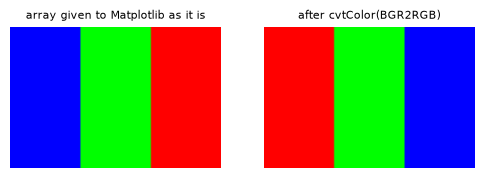

In [5]:
toy_flag = np.zeros((60, 90, 3), dtype=np.uint8)        # (height, width, channels)
toy_flag[:, 0:30] = (0, 0, 255)       # intended: red, written as B, G, R
toy_flag[:, 30:60] = (0, 255, 0)      # green
toy_flag[:, 60:90] = (255, 0, 0)      # intended: blue
print("shape:", toy_flag.shape, "| dtype:", toy_flag.dtype, "| pixel [0, 0] =", toy_flag[0, 0])

fig, axs = plt.subplots(1, 2, figsize=(6, 2))
axs[0].imshow(toy_flag); axs[0].set_title("array given to Matplotlib as it is", fontsize=8)
axs[1].imshow(cv2.cvtColor(toy_flag, cv2.COLOR_BGR2RGB)); axs[1].set_title("after cvtColor(BGR2RGB)", fontsize=8)
for ax in axs: ax.axis("off")
plt.show()

### 🧭 Think T3.2
> Why is the left band blue in the first panel? Which function in the pipeline "OpenCV array → screen" made the wrong assumption: `cv2.imread` or `plt.imshow`?

OpenCV gives the channels as B, G, R, and `plt.imshow` reads them as R, G, B, so red and blue swap. Matplotlib makes the wrong assumption.

### 3. Resizing: `dsize` and interpolation

`cv2.resize(src, dsize, fx, fy, interpolation)` takes **either** a target size `dsize` **or** two scale factors `fx`, `fy` (with `dsize=None`). Read the description of `dsize` in the [`resize` documentation](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html) (Ctrl+F `resize()` on that page, then read the `dsize` parameter): in which order does it expect the two numbers? Example 3.2 uses the scale-factor form, so the order question stays yours.

### ▶️ Example 3.2 — Resizing by scale factors

**What this example shows:** the toy flag shrunk to half its width and stretched to double its height, with `fx` and `fy`.

In [6]:
toy_tall = cv2.resize(toy_flag, None, fx=0.5, fy=2.0, interpolation=cv2.INTER_NEAREST)
print("original shape", toy_flag.shape, "-> fx=0.5, fy=2.0 ->", toy_tall.shape)

original shape (60, 90, 3) -> fx=0.5, fy=2.0 -> (120, 45, 3)


### 🧭 Think T3.3
> From Example 3.2: does `fx` scale the first or the second number of `shape`? Then, from the `dsize` description in the [`resize` documentation](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html): the statement asks for "448x336" (width × height, as in T3.1). What exactly will you pass as `dsize`, and what `shape` do you expect after resizing a colour image?

Example 3.2 halved the second number of `shape` (90 → 45 columns), so `fx` scales the width and `fy` the height. `dsize` is (width, height), so for 448 × 336 we pass `dsize = (448, 336)`. The resized colour image has `shape = (336, 448, 3)`: height first, then width, then the 3 channels.

### 🧭 Think T3.4
> Look at the size of *your* photo (file properties, or `shape` after loading). Which scale factor takes its width to 448, and which takes its height to 336? Are they equal? What would happen to the objects in a portrait photo, and what would you do about it?

My photo is 5712 × 4284. The factor for the width is 448 / 5712 ≈ 0.0784 and for the height 336 / 4284 ≈ 0.0784. They are equal, so the photo keeps its proportions and objects are not distorted (circles stay circles). A portrait photo (4284 × 5712) forced to 448 × 336 would get 0.105 for the width and 0.059 for the height, so objects would be squashed vertically. To avoid it, rotate the photo to landscape or crop it to 4:3 before resizing.

### 4. Shrinking without destroying the image

Going from about 4000 columns to 448 means each new pixel stands for about 9 × 9 original pixels. An interpolation method decides what value it gets. `INTER_NEAREST` copies **one** of the original pixels. `INTER_AREA` **averages** all the original pixels that fall inside the new one. F&P §4.4 explains what can go wrong when a fine pattern is *sampled* on a coarser grid. Example 3.3 shows it on the finest pattern there is.

### ▶️ Example 3.3 — A checkerboard shrunk two ways

**What this example shows:** a 200 × 200 checkerboard of 1-pixel squares shrunk to 50 × 50 (square sizes, so no width/height question here).

mean grey of the original: 127.5
INTER_NEAREST -> values [0] | INTER_AREA -> values [128] | INTER_CUBIC -> values [128]


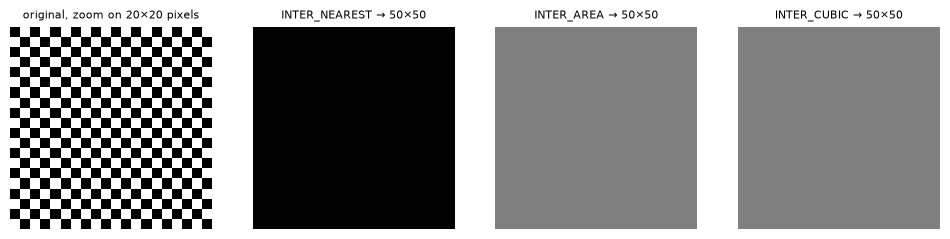

In [7]:
toy_checker = ((np.indices((200, 200)).sum(axis=0) % 2) * 255).astype(np.uint8)
toy_near = cv2.resize(toy_checker, (50, 50), interpolation=cv2.INTER_NEAREST)
toy_area = cv2.resize(toy_checker, (50, 50), interpolation=cv2.INTER_AREA)
toy_cubic = cv2.resize(toy_checker, (50, 50), interpolation=cv2.INTER_CUBIC)
print("mean grey of the original:", toy_checker.mean())
print("INTER_NEAREST -> values", np.unique(toy_near), "| INTER_AREA -> values", np.unique(toy_area), "| INTER_CUBIC -> values", np.unique(toy_cubic))

fig, axs = plt.subplots(1, 4, figsize=(12, 3))
axs[0].imshow(toy_checker[:20, :20], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axs[0].set_title("original, zoom on 20×20 pixels", fontsize=8)
axs[1].imshow(toy_near, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axs[1].set_title("INTER_NEAREST → 50×50", fontsize=8)
axs[2].imshow(toy_area, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axs[2].set_title("INTER_AREA → 50×50", fontsize=8)
axs[3].imshow(toy_cubic, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axs[3].set_title("INTER_CUBIC → 50×50", fontsize=8)
for ax in axs:
    ax.axis("off")
plt.show()

### 🧭 Think T3.5
> What grey *should* a viewer see when looking at this checkerboard from far away? Which method gives it? The other one produced a uniform but wrong image: that is called **aliasing**. Using the words *sampling*, *fine detail (high frequencies)* and *averaging*, which interpolation will you use to shrink your photo, and why?

From far away the checkerboard looks mid grey: the average of half 0 and half 255 is 127.5. `INTER_AREA` gives it (128). `INTER_NEAREST` gave a uniform black image, which is wrong: that false result is aliasing. To shrink my photo I use `INTER_AREA`, because sampling (`INTER_NEAREST`) keeps one pixel at the same position of every block and depends on luck, while averaging takes the mean of the whole block, so fine detail becomes its average tone instead of a false pattern.

### 5. Reading and saving: what can silently go wrong

- `cv2.imread` does **not** raise an error when it cannot read a file. It returns `None` and prints a warning on the console, and the error appears later, elsewhere: `'NoneType' object has no attribute 'shape'`.
- iPhones save **HEIC** by default, which OpenCV cannot read: set *Settings → Camera → Formats → Most Compatible*, or export as JPEG.
- On Windows, `imread`/`imwrite` can fail on paths with accents. Older OpenCV versions also reject `pathlib.Path` objects: pass `str(path)`.
- **JPEG** is lossy: each save recompresses and changes pixel values slightly. **PNG** is lossless.

### 🧭 Think T3.6
> Every later part starts from your resized scene. Why save it as PNG rather than JPEG? And what should `load_bgr` do when `imread` returns `None`, so that a typo in a file name is found immediately and not three cells later?

The resized scene is the input of every later exercise, so I save it as PNG. PNG is lossless and gives back exactly the same pixels, while JPEG recompresses at every save and adds artefacts around edges and fine texture, which is exactly what Gabor, Canny and the pyramids measure. `cv2.imread` returns `None` without raising an error when it cannot read a file, so `load_bgr` checks the result and raises a `FileNotFoundError` with the path right away. A typo in a file name then stops the program in the same cell, instead of crashing later in another cell with an unclear message.

### 6. Showing an image

**With OpenCV** (what the statement asks): `cv2.imshow(window_name, img)` draws the array in a native window, as BGR, without changing values. The window is only drawn while `cv2.waitKey(ms)` runs: it waits `ms` milliseconds for a key (`0` = forever) and returns the key code. `cv2.destroyWindow(name)` / `cv2.destroyAllWindows()` close windows.
- **Windows:** the window may open behind VS Code (look at the taskbar).
- **macOS:** the window sometimes stays after closing. One extra `cv2.waitKey(1)` after `destroyAllWindows()` lets OpenCV process the close. If the kernel freezes, press a key in the window, or restart the kernel and set `USE_CV_WINDOWS = False`.

**With Matplotlib** (what you paste in the report): `plt.imshow` inside a figure, `fig.savefig(path, dpi=200, bbox_inches="tight")` to save. For a 2-D array Matplotlib applies a colormap and, by default, stretches the values between their minimum and maximum.

### ▶️ Example 3.4 — Two OpenCV windows that close by themselves

**What this example shows:** the window calls, with a 1.5-second timeout instead of a key press, on two toy images.

In [8]:
if USE_CV_WINDOWS:
    cv2.imshow("toy A", cv2.resize(toy_flag, None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST))
    cv2.imshow("toy B", toy_checker)
    toy_code = cv2.waitKey(1500)            # wait at most 1.5 s, -1 if no key was pressed
    cv2.destroyWindow("toy A")
    cv2.destroyWindow("toy B")
    cv2.waitKey(1)
    print("waitKey returned", toy_code)
else:
    print("USE_CV_WINDOWS is False: skipped")

waitKey returned -1


**What to notice:** the flag is right in the OpenCV window without conversion (T3.2). `waitKey` with a positive number returns `-1` when the time runs out. `fx=4` with `INTER_NEAREST` enlarges pixel art without blurring it.

### ▶️ Example 3.5 — Grids of axes and honest grey levels

**What this example shows:** (a) what `plt.subplots` returns for a grid, and how to reach every axis with one loop variable, (b) a grey image with and without fixed limits.

axes array shape: (2, 3) -> flattened: (6,)


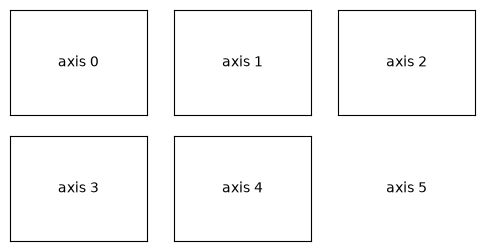

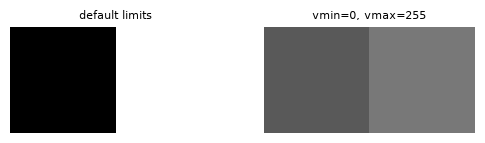

plt.subplots(1, 1) returns a single Axes: Axes


In [9]:
fig, toy_axs = plt.subplots(2, 3, figsize=(6, 3))
print("axes array shape:", toy_axs.shape, "-> flattened:", toy_axs.ravel().shape)
for toy_k, ax in enumerate(toy_axs.ravel()):
    ax.text(0.5, 0.5, f"axis {toy_k}", ha="center", va="center"); ax.set_xticks([]); ax.set_yticks([])
toy_axs.ravel()[-1].axis("off")                     # an axis can be hidden entirely
plt.show()

toy_dim = np.full((20, 40), 90, np.uint8); toy_dim[:, 20:] = 120      # two dark greys
fig, toy_axs2 = plt.subplots(1, 2, figsize=(6, 1.6))
toy_axs2[0].imshow(toy_dim, cmap="gray"); toy_axs2[0].set_title("default limits", fontsize=8)
toy_axs2[1].imshow(toy_dim, cmap="gray", vmin=0, vmax=255); toy_axs2[1].set_title("vmin=0, vmax=255", fontsize=8)
for ax in toy_axs2: ax.axis("off")
plt.show()
print("plt.subplots(1, 1) returns a single Axes:", type(plt.subplots(1, 1)[1]).__name__); plt.close("all")

### 🧭 Think T3.7
> In the second figure, which panel tells the truth about the two greys (90 and 120 out of 255)? When will you want fixed limits, and when automatic ones (think of a grey photo versus a filter response with negative values)? And from the first figure: why is `.ravel()` handy when the number of images is not a multiple of the number of columns?

The panel with fixed limits (0–255) tells the truth: 90 and 120 look like a dark and a mid grey. With automatic limits Matplotlib stretches the smallest value to black and the largest to white, so 90 and 120 look like black and white. Fixed limits for a grey photo, where the values are brightness, and automatic limits for a filter response with negative or float values. `.ravel()` flattens the 2-D grid of axes into one list, so one loop fills every panel and switches off the empty ones.

### ❓ Question Q3.1
> Put T3.2, T3.6 and T3.7 together: in your module, in which function(s) will you convert BGR to RGB, and where must you *not* convert? Why is it a bad idea to store an RGB version of your scene and pass it around? *(Where to read: Theory sections 2 and 6.)*

Only in the display function (`show_images`, colour branch): convert a copy to RGB right before `plt.imshow`. Never in `load_bgr`, `resize_to`, `to_gray`, or before `cv2.imshow`, `cv2.imwrite` or `cv2.cvtColor(..., COLOR_BGR2GRAY)`, because OpenCV expects BGR everywhere. An RGB copy passed around would reach those OpenCV calls with red and blue swapped: wrong grey weights, and saved images with swapped colours.

## ✍️ Your task 3 — `a1_image.py`, the image helpers of the whole assignment

**Why.** Every later part loads, converts and shows images. Written once and tested, the three classic bugs (silent `None`, swapped width/height, swapped colours) disappear from the rest of the assignment.

**The contract**

```python
def load_bgr(path) -> np.ndarray                  # (H, W, 3) uint8 BGR. FileNotFoundError if unreadable
def resize_to(img, size=(448, 336)) -> np.ndarray # size = (width, height)
def to_gray(img) -> np.ndarray                     # (H, W) uint8. A 2-D input comes back as a copy
def to_uint8(arr) -> np.ndarray                    # any 2-D array stretched to 0..255 uint8, for display
def show_images(images, titles=None, cols=3, figsize=None) -> matplotlib.figure.Figure
def show_with_opencv(img, window="image") -> int   # window until a key is pressed, returns the key code
```

**Requirements**

- `load_bgr`: T3.6. `resize_to`: T3.3 and T3.5. `to_gray`: OpenCV has a colour-conversion code for BGR to grey.
- `to_uint8`: the minimum maps to 0, the maximum to 255, linearly. A constant array (no range) returns zeros, without dividing by zero. Display only, never before computing.
- `show_images`: one figure, a grid with `cols` columns and as many rows as needed. Colour images are shown in their true colours (T3.2), `uint8` grey images with honest limits, float images with automatic limits (T3.7). Titles if given, every axis hidden, unused ones too. It must **return** the figure and not call `plt.show()` (the caller decides to show or to save). It must work for 1 image as well as for 7.
- `show_with_opencv`: waits for a key, closes its window cleanly on both systems (section 6), returns the key code.

In [10]:
%%writefile helpers/a1_image.py
"""Exercise 3 and helpers used by every other part: loading, resizing, grey conversion and display."""
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt

def load_bgr(path):
    """Read a colour image from disk. Returns an (H, W, 3) uint8 array in BGR order.

    Raises FileNotFoundError when OpenCV cannot read the file (cv2.imread returns None instead of raising).
    """

    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image from {path}")

    return image


def resize_to(img, size=(448, 336)):
    """Resize to size = (width, height), with the interpolation suited to shrinking (T3.5)."""

    resized = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    return resized


def to_gray(img):
    """BGR (H, W, 3) -> grey (H, W) uint8. A 2-D input is returned as a copy."""

    if img.ndim == 2:
        return img.copy()
    else:
        return cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)



def to_uint8(arr):
    """Linear min-max stretch of any 2-D array to 0..255, as uint8. For DISPLAY only.

    A constant array (max == min) returns an array of zeros.
    """
    min_val = np.min(arr)
    max_val = np.max(arr)

    if max_val == min_val:
        return np.zeros_like(arr, dtype=np.uint8)

    out = (arr - min_val) / (max_val - min_val) * 255
    return np.round(out).astype(np.uint8)

def show_images(images, titles=None, cols=3, figsize=None):
    """Draw a grid of images with Matplotlib and RETURN the figure (no plt.show inside).

    images  -- list of arrays: (H, W, 3) BGR uint8, (H, W) uint8 grey, or (H, W) float
    titles  -- list of strings (same length) or None
    cols    -- images per row
    figsize -- (width, height) in inches, or None for an automatic size
    Colour images in true colours, uint8 grey with limits 0..255, float with automatic limits, axes hidden.
    """
    N = len(images)
    rows = math.ceil(N / cols)
    if figsize is None:
        figsize = (cols * 3, rows * 3)
    fig, axs = plt.subplots(rows, cols, figsize=figsize)
    axs = np.array(axs).reshape(-1)        # flatten, even if rows == 1 or cols == 1
    for k, ax in enumerate(axs):
        if k < N:
            img = images[k]
            if img.ndim == 3 and img.shape[2] == 3:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            elif img.ndim == 2 and img.dtype == np.uint8:
                ax.imshow(img, cmap="gray", vmin=0, vmax=255)
            else:
                ax.imshow(img, cmap="gray")
            if titles is not None:
                ax.set_title(titles[k], fontsize=8)
        ax.axis("off")

    return fig


def show_with_opencv(img, window="image"):
    """Show `img` (BGR or grey) in a native OpenCV window until a key is pressed. Returns the key code."""
    
    key = -1
    if img.dtype != np.uint8:
        print("⚠️ show_with_opencv: the image is not uint8, it will be converted for display")
        img = to_uint8(img)
        
    cv2.imshow(window, img)
    while True:
        key = cv2.waitKey(100)                                   # wait 0.1 s for a key
        if key != -1:                                            # a key was pressed
            break
        if cv2.getWindowProperty(window, cv2.WND_PROP_VISIBLE) < 1:   # the window was closed with X
            break
    if cv2.getWindowProperty(window, cv2.WND_PROP_VISIBLE) >= 1:     # still open: close it ourselves
        cv2.destroyWindow(window)
    cv2.waitKey(1)                                               # let the window actually close (macOS)
    return key

def save_figure(fig, path, dpi=150):
    """Save a Matplotlib or image figure to disk with the given DPI. The figure is not closed."""
    if isinstance(fig, plt.Figure):
        fig.savefig(str(path), dpi=dpi, bbox_inches="tight")
    elif isinstance(fig, np.ndarray):
        cv2.imwrite(str(path), fig)
    else:
        raise TypeError(f"save_figure: expected plt.Figure or np.ndarray, got {type(fig).__name__}")

Overwriting helpers/a1_image.py


### ✅ Test 3

In [11]:
import a1_image as im
from matplotlib.figure import Figure

tmp = DATA_DIR / "_test3.png"
fake = np.zeros((1344, 1792, 3), dtype=np.uint8)
fake[..., 0] = 255                                            # pure blue in BGR
fake[::4, ::4] = 0                                            # sparse black dots: the interpolation matters
cv2.imwrite(str(tmp), fake)

loaded = im.load_bgr(tmp)
assert loaded.shape == (1344, 1792, 3) and loaded.dtype == np.uint8
try:
    im.load_bgr(DATA_DIR / "does_not_exist.png")
    raise AssertionError("load_bgr must raise FileNotFoundError for a missing file (T3.6)")
except FileNotFoundError:
    pass

small = im.resize_to(loaded)
assert small.shape == (336, 448, 3), f"expected (336, 448, 3), got {small.shape} (T3.3)"
assert abs(small[..., 0].mean() - 239) < 2, "shrinking must average the fine pattern, not sample it (T3.5)"
assert im.resize_to(loaded[..., 0], (100, 50)).shape == (50, 100)

g = im.to_gray(small)
assert g.shape == (336, 448) and g.dtype == np.uint8
assert im.to_gray(g) is not g and np.array_equal(im.to_gray(g), g)

u = im.to_uint8(np.array([[-2.0, 0.0], [2.0, 6.0]]))
assert u.dtype == np.uint8 and u.min() == 0 and u.max() == 255
assert np.array_equal(im.to_uint8(np.full((3, 3), 7.0)), np.zeros((3, 3), np.uint8))

fig = im.show_images([small, g, g.astype(np.float32)], ["colour", "grey", "float"], cols=2)
assert isinstance(fig, Figure), "show_images must return the figure"
shown = np.asarray(fig.axes[0].images[0].get_array())
assert shown[1, 1, 2] > 200 and shown[1, 1, 0] == 0, "colour images must be shown in true colours (T3.2): blue is shown as red?"
assert fig.axes[1].images[0].get_clim() == (0, 255), "uint8 grey images need fixed limits 0..255 (T3.7)"
assert len(fig.axes) >= 3
plt.close(fig)
fig1 = im.show_images([g]); assert isinstance(fig1, Figure), "one single image must work too"; plt.close(fig1)
tmp.unlink()
print("✅ Part 3 OK")

✅ Part 3 OK


### 🛠️ Use it — your scene

1. Take the photo: landscape, 4:3 (T3.4), good light, many objects with edges at many orientations, some fine texture and some large smooth areas (Parts 4 to 6 need all of these). Copy it into `data/` with a plain ASCII name, as JPEG or PNG (section 5).
2. Load it, print its original `shape`, resize it, print the new `shape`.
3. Save the resized scene as `data/scene_448x336.png` (T3.6). From now on: `SCENE = im.load_bgr(DATA_DIR / "scene_448x336.png")` and `GRAY = im.to_gray(SCENE)`.
4. Show it with `im.show_with_opencv` (if `USE_CV_WINDOWS`): the call the statement asks for.
5. Show colour and grey with `im.show_images`, save `figures/fig3_scene.png`.
6. For the report: the read, resize and show lines, the original and final sizes, and one sentence on your interpolation choice (T3.5).

In [12]:
import a1_image as im


PHOTO = DATA_DIR / "my_scene.png"          # TODO: the name of your photo
# TODO: load, print the original shape, resize, print the new shape, save scene_448x336.png

scene = im.load_bgr(PHOTO)
print("Original shape:", scene.shape)
scene_resized = im.resize_to(scene, (448, 336))
print("New shape:", scene_resized.shape)
cv2.imwrite(str(DATA_DIR / "scene_448x336.png"), scene_resized)

# TODO: SCENE = ..., GRAY = ...
SCENE = im.load_bgr(DATA_DIR / "scene_448x336.png")
GRAY = im.to_gray(SCENE)

cv2.imwrite(str(FIG_DIR / "fig3_scene.png"), SCENE)
cv2.imwrite(str(FIG_DIR / "fig3_gray.png"), GRAY)

# TODO: show with OpenCV (if USE_CV_WINDOWS) and with show_images, save figures/fig3_scene.png
im.show_with_opencv(SCENE, "Scene (BGR)")
im.show_with_opencv(GRAY, "Scene (GRAY)")

Original shape: (4284, 5712, 3)
New shape: (336, 448, 3)


13

---
# Part 4 — Exercise 4: a Gabor filter at 4 orientations (4 points)

> *Statement.* Apply a Gabor filter at 4 orientations. Combine (use the maximum value for each pixel) the four orientations into one filtered image and show the result. Play with the parameters of the filter and show how the filter works with 3 different parameter set values.

> 📖 **Read before you start this part** (60 min)
> - **F&P §4.1–4.2** *Linear Filters and Convolution*, *Shift Invariant Linear Systems* (§4.2.3 *Edge Effects*). Look for: a filter as a weighted sum over a neighbourhood.
> - **F&P §4.5** *Filters as Templates* (§4.5.1 *Convolution as a Dot Product*). Look for: why a filter responds most where the image *looks like* the kernel. Everything in this part rests on that idea.
> - **F&P §6.1** *Local Texture Representations Using Filters* (§6.1.1 *Spots and Bars*). Look for: banks of oriented filters at several scales.
> - **[Sz §3.2, p. 119](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=145>)** *Linear filtering*, the band-pass and steerable filters ([§3.2.3, p. 127](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=153>)), where Gabor filters are discussed.
> - **[L1](<../../Slides/Lecture 1.pdf>) p. 21** and the class at [00:37]: the visual cortex V1. Gabor functions are the classic model of V1 *simple cells* (J. Daugman, *JOSA A* 2(7), 1985, [link](https://doi.org/10.1364/JOSAA.2.001160)).
> - OpenCV docs: [`getGaborKernel`, `filter2D`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html). On each OpenCV page, press Ctrl+F and type the function name to jump to it.

## Theory, step by step

### 1. A filter is a template

A linear filter replaces each pixel by a weighted sum of its neighbours. The weights form a small array, the **kernel**. `cv2.filter2D(src, ddepth, kernel)` computes this sum at every pixel (strictly a *correlation*: the kernel is not flipped, which makes no difference for a kernel that is symmetric under a 180° rotation). `ddepth` is the type of the output: `-1` means "the same type as the input", `cv2.CV_32F` means `float32`.

F&P §4.5.1 reads this sum as a **dot product** between the kernel and the image patch under it. Example 4.1 shows what that means with a hand-made kernel that has nothing to do with Gabor.

### ▶️ Example 4.1 — A "spot detector" and the output type

**What this example shows:** a 3 × 3 kernel with a positive centre and a negative surround, applied to a toy image containing a single bright dot, a bright horizontal line and a flat bright square. Then the same filtering with two different `ddepth`.

In [13]:
toy_spot_k = np.array([[-1, -1, -1],
                       [-1,  8, -1],
                       [-1, -1, -1]], np.float32)
toy_scene = np.zeros((40, 60), np.float32)
toy_scene[10, 10] = 1.0                    # a dot
toy_scene[30, 5:25] = 1.0                  # a horizontal line
toy_scene[8:22, 35:55] = 1.0               # a flat square
toy_out = cv2.filter2D(toy_scene, cv2.CV_32F, toy_spot_k)
print("on the dot       :", toy_out[10, 10])
print("on the line      :", toy_out[30, 15])
print("inside the square:", toy_out[15, 45], "| just outside it:", toy_out[15, 34])

toy_u8 = (toy_scene * 200).astype(np.uint8)
print("ddepth=-1     :", cv2.filter2D(toy_u8, -1, toy_spot_k).dtype, "min", cv2.filter2D(toy_u8, -1, toy_spot_k).min())
print("ddepth=CV_32F :", cv2.filter2D(toy_u8, cv2.CV_32F, toy_spot_k).dtype, "min", cv2.filter2D(toy_u8, cv2.CV_32F, toy_spot_k).min())

on the dot       : 8.0
on the line      : 6.0
inside the square: 0.0 | just outside it: -3.0
ddepth=-1     : uint8 min 0
ddepth=CV_32F : float32 min -600.0


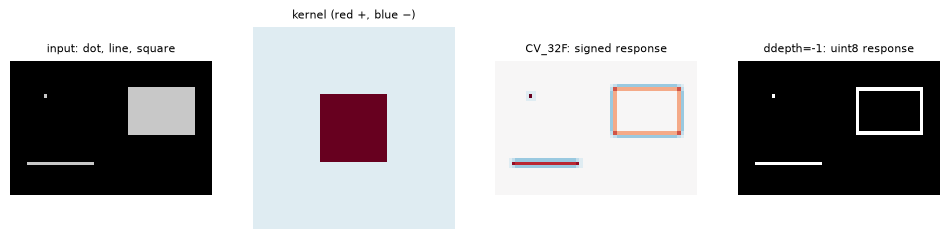

In [14]:
out_u8 = cv2.filter2D(toy_u8, -1, toy_spot_k)
out_f = cv2.filter2D(toy_u8, cv2.CV_32F, toy_spot_k)
m = np.abs(out_f).max()

fig, axs = plt.subplots(1, 4, figsize=(12, 3))
axs[0].imshow(toy_u8, cmap="gray", vmin=0, vmax=255)
axs[0].set_title("input: dot, line, square", fontsize=8)
axs[1].imshow(toy_spot_k, cmap="RdBu_r", vmin=-8, vmax=8)
axs[1].set_title("kernel (red +, blue −)", fontsize=8)
axs[2].imshow(out_f, cmap="RdBu_r", vmin=-m, vmax=m)
axs[2].set_title("CV_32F: signed response", fontsize=8)
axs[3].imshow(out_u8, cmap="gray", vmin=0, vmax=255)
axs[3].set_title("ddepth=-1: uint8 response", fontsize=8)
for ax in axs:
    ax.axis("off")
plt.show()

### 🧭 Think T4.1
> (a) Rank the dot, the line and the inside of the square by response, and explain the ranking with "the response is large where the patch looks like the kernel".
> (b) The square gives zero inside: why? What property of this kernel's weights causes it?
> (c) What did `ddepth=-1` do to the negative values, and why would that be a problem for a filter whose answers can be negative?

(a) The dot gives the largest response (8): all 8 neighbours are dark, so only the +8 centre counts, and the patch looks exactly like the kernel. The middle of the line comes next (6): two of its neighbours are bright and each takes 1 away. Inside the square the response is 0.
(b) The 9 weights add up to 8 − 8 = 0, so on any flat region, dark or bright, the positive centre and the negative neighbours cancel. At the edge of the square the response is 8 − 5 = 3, and just outside it 3 × (−1) = −3: the filter answers negative next to bright structures.
(c) With `ddepth=-1` the output stays `uint8`, which only holds 0–255, so every negative answer is cut to 0: they all turn black and a weak negative can no longer be told from a strong one. A filter with signed answers, like Gabor, must be computed in float (`CV_32F`).

### 2. The Gabor kernel

A Gabor function is a **sinusoidal wave** (the carrier) inside a **Gaussian window** (the envelope). OpenCV builds

$$
g(x,y) = \exp\!\left(-\frac{x'^2 + \gamma^2 y'^2}{2\sigma^2}\right)\cos\!\left(2\pi\frac{x'}{\lambda} + \psi\right),
\qquad
\begin{aligned} x' &= x\cos\theta + y\sin\theta\\ y' &= -x\sin\theta + y\cos\theta\end{aligned}
$$

with $(x, y)$ measured from the centre of the kernel. `cv2.getGaborKernel(ksize, sigma, theta, lambd, gamma, psi, ktype)` returns this array. Its six numbers: `ksize` (the size of the array, a tuple), $\sigma$ (width of the Gaussian), $\theta$ (orientation, radians), $\lambda$ (wavelength of the wave, in pixels), $\gamma$ (aspect ratio of the Gaussian), $\psi$ (phase of the wave). **Careful:** OpenCV's default for `psi` is $\pi/2$, and `ktype` defaults to `float64`.

Rather than a table of effects, Example 4.2 lets you *see* them: it only draws kernels, it never filters anything.

### ▶️ Example 4.2 — A kernel gallery

**What this example shows:** a small helper that draws Gabor kernels side by side, at an arbitrary orientation of 60°, here varying only $\lambda$. Edit the last line to vary the other parameters (T4.2 asks you to).

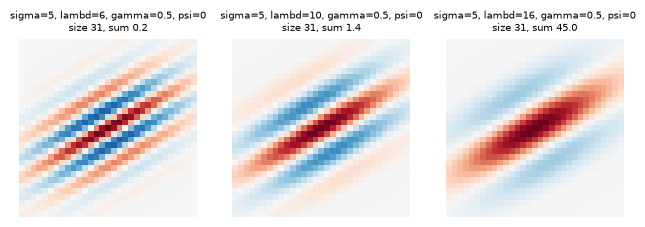

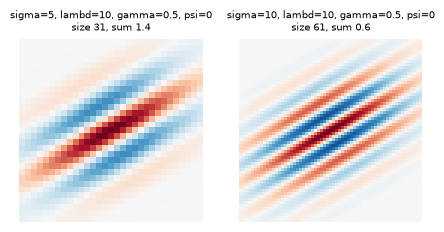

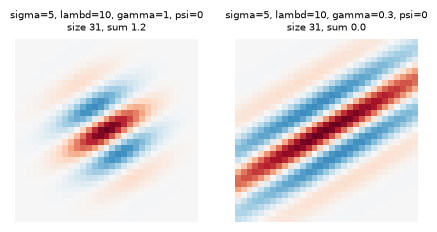

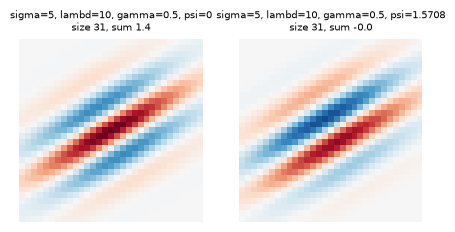

In [15]:
def toy_gallery(variants, theta_deg=60):
    # variants: list of dicts with sigma, lambd, gamma, psi; ksize follows sigma
    fig, axs = plt.subplots(1, len(variants), figsize=(2.6 * len(variants), 2.8))
    for ax, v in zip(np.atleast_1d(axs), variants):
        ks = int(6 * v["sigma"]) | 1                      # "| 1" makes the number odd
        kern = cv2.getGaborKernel((ks, ks), v["sigma"], np.deg2rad(theta_deg), v["lambd"], v["gamma"], v["psi"])
        ax.imshow(kern, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_title(", ".join(f"{k}={val:g}" for k, val in v.items()) + f"\nsize {kern.shape[0]}, sum {kern.sum():.1f}", fontsize=7)
        ax.axis("off")
    plt.show()

toy_base = {"sigma": 5.0, "lambd": 10.0, "gamma": 0.5, "psi": 0.0}
toy_gallery([dict(toy_base, lambd=6.0), toy_base, dict(toy_base, lambd=16.0)])
toy_gallery([dict(toy_base, sigma=5.0), dict(toy_base, sigma=10.0)])          # (b) σ
toy_gallery([dict(toy_base, gamma=1.0), dict(toy_base, gamma=0.3)])           # (c) γ
toy_gallery([dict(toy_base, psi=0.0), dict(toy_base, psi=np.pi / 2)])         # (d) ψ

**What to notice:** red is positive, blue negative, white zero. `dict(toy_base, lambd=6.0)` copies the dictionary and changes one key. A kernel is just a small array you can plot, which is the fastest way to check any kernel you build.

### 🧭 Think T4.2
> Using the gallery (change one parameter at a time in the last line, rerun):
> (a) What does $\lambda$ change in the picture? So, to which width of structure in an image will the kernel respond best (think of T4.1)?
> (b) Double $\sigma$ with $\lambda$ fixed: what changes in the number of visible stripes? Would that make the filter more or less picky about the exact width and orientation of a structure?
> (c) Set $\gamma$ to 1, then 0.3: how does the shape of the window change, relative to the direction of the stripes?
> (d) Compare $\psi = 0$ and $\psi = \pi/2$ (`np.pi / 2`): which one is symmetric around the centre, which one is positive on one side and negative on the other? Which looks like a *bar*, which like a *step* between a dark and a light region?

(a) λ is the spacing between stripes (the wavelength). A small λ makes thin stripes, so the kernel responds best to thin structures. A large λ responds to thick ones.
(b) With λ fixed, σ = 5 shows about 5 stripes and σ = 10 about 9. A bigger window makes the filter more picky: all its stripes must line up with the image, so it only answers to structures with almost the exact width and orientation.
(c) With γ = 1 the window is round. With γ = 0.3 it is stretched along the stripes, so each stripe becomes a longer segment and the filter prefers long straight structures.
(d) ψ = 0 is symmetric around the centre (negative, positive, negative): it looks like a thin bar, such as a bright cable on a dark floor. ψ = π/2 is positive on one side and negative on the other: it looks like a step between a dark and a light region, such as the edge of a table.

### 🧭 Think T4.3
> The gallery chose `ksize` $\approx 6\sigma$, made odd. Why about $6\sigma$ (what fraction of a Gaussian lies within $\pm3\sigma$)? What would a kernel with `ksize` much smaller than $6\sigma$ look like, and why would it be a bad filter? Why odd?

About 99.7 % of a Gaussian lies within ±3σ of its centre, so a canvas of about 6σ (3σ on each side) contains essentially the whole window. A ksize much smaller than 6σ cuts the window off while it is still large: the kernel stops abruptly at a square border instead of fading to 0. That hard border acts as an extra edge and makes the window square, so the filter loses its clean preference for one width and one orientation. ksize must be odd so that the kernel has a single centre pixel (31 → pixel 15 with 15 on each side). With an even size the centre falls between two pixels and every response is shifted by half a pixel.

### 3. Which way the stripes point

The stripes are the lines where the wave $\cos(2\pi x'/\lambda + \psi)$ is constant, that is where $x'$ is constant. OpenCV's [`getGaborKernel` documentation](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html) (Ctrl+F `getGaborKernel`) describes $\theta$ as *the orientation of the normal to the parallel stripes*.

### 🧭 Think T4.4
> Put $\theta = 0$ in the formula for $x'$. Along which image axis does the wave vary, and so are the stripes vertical or horizontal? Using T4.1, which structures in a desk scene respond most to $\theta = 0$? And to $\theta = \pi/2$? (Check by drawing a kernel with `toy_gallery(..., theta_deg=0)`.)

With θ = 0, x' = x, so the wave changes from left to right and the stripes are vertical. The kernel matches structures that run in the same direction as its stripes: θ = 0 responds most to vertical structures, such as the legs and pole of the floor lamp, the chair legs, the corners between walls and the left and right sides of the TV. θ = π/2 has horizontal stripes and responds to horizontal structures, such as the top and bottom of the TV, the top of the sofa backrest and the front edge of the table. A structure that crosses the stripes covers positive and negative parts equally, so its response cancels out.

### 🧭 Think T4.5
> Replace $\theta$ by $\theta + \pi$: what happens to $x'$? With $\psi = 0$, what happens to the kernel (the cosine is even)? So which interval of angles contains all the *different* orientations, and which four evenly spaced angles would you pick? Would $\theta + \pi$ bring anything new with $\psi = \pi/2$?

Replacing θ by θ + π changes x' into −x'. With ψ = 0 the cosine is even, so the kernel is exactly the same: all the different orientations lie in [0, π). Four evenly spaced angles are 0°, 45°, 90° and 135° (0, π/4, π/2, 3π/4 in radians); 180° would repeat 0°. With ψ = π/2 the kernel is odd, so θ + π gives the same orientation with the opposite sign: a step from dark to light instead of light to dark.

### 4. The sign of the answer

With $\psi = 0$ the kernel has a positive central stripe and negative stripes beside it, and, unlike the spot kernel of Example 4.1, its weights do **not** sum exactly to zero (see the sums in the gallery).

### 🧭 Think T4.6
> Using the template idea of T4.1, at the centre of each structure, with $\theta$ matching its orientation: what sign does the response have for (a) a thin bright cable on a dark floor, (b) a thin dark cable on a light desk, (c) a large flat bright wall? (No computation needed, just the sign and "large/small".)

(a) A thin bright cable on a dark floor looks like the kernel (bright centre, darker sides): large positive response.
(b) A thin dark cable on a light desk is the opposite pattern: large negative response.
(c) A large flat bright wall has no structure, but the Gabor weights do not add up to zero, so the response is positive and small compared with a cable, not exactly zero.

### 5. Several answers per pixel, and reducing them to one

Filtering one image with $K$ kernels gives $K$ images of the same size. `np.stack(list_of_arrays, axis=0)` puts them on top of each other into one array of shape `(K, H, W)`. A **reduction** along an axis (`.mean(axis=…)`, `.min(axis=…)`, `.max(axis=…)`, `.argmin(axis=…)`) collapses that axis, element by element. Example 4.3 shows it on a different kind of data.

### ▶️ Example 4.3 — Reductions along an axis: temperatures

**What this example shows:** three cities, temperatures over five days, stacked and reduced.

In [16]:
toy_cities = ["Coruña", "Vigo", "Lugo"]
toy_temps = [np.array([14, 15,  8, 12, 16]),
             np.array([16, 17, 15, 15, 18]),
             np.array([10, 12,  9,  8, 13])]
toy_T = np.stack(toy_temps, axis=0)                 # shape (3 cities, 5 days)
print("shape:", toy_T.shape)
print("mean of each day over the cities :", toy_T.mean(axis=0))
print("coldest value of each day        :", toy_T.min(axis=0))
print("which city was coldest each day  :", [toy_cities[i] for i in toy_T.argmin(axis=0)])
print("mean of each city over the days  :", toy_T.mean(axis=1))

shape: (3, 5)
mean of each day over the cities : [13.3333 14.6667 10.6667 11.6667 15.6667]
coldest value of each day        : [10 12  8  8 13]
which city was coldest each day  : ['Lugo', 'Lugo', 'Coruña', 'Lugo', 'Lugo']
mean of each city over the days  : [13.  16.2 10.4]


### 🧭 Think T4.7
> In Example 4.3, what does `axis=0` mean in words, and what does `axis=1` mean? Your Gabor responses will have shape `(4, H, W)`: which reduction, along which axis, gives "the strongest of the four answers at every pixel"? Which other reduction would tell you *which orientation* won?

In Example 4.3, axis=0 collapses the cities: min(axis=0) gives, for each day, the coldest temperature among the three cities. axis=1 collapses the days: mean(axis=1) gives, for each city, its average over the five days. My Gabor responses have shape (4, H, W), so max(axis=0) gives, at every pixel, the strongest of the four answers: one (H, W) image. argmax(axis=0) tells which orientation won at each pixel (0, 1, 2 or 3).

### ❓ Question Q4.1
> Combine T4.6 and T4.7. "Use the maximum value for each pixel": the maximum of the four *signed* responses, or of their *absolute values*? What does each version keep and lose for the dark cable of T4.6 (b)? Which will you use, and what one-sentence justification will you write in the report?

At the centre of a dark cable, the matching orientation gives a large negative answer and the other three give small answers. With the signed maximum, one of those small answers wins and the dark cable disappears from the combined image: only bright structures survive. With the maximum of the absolute values, the large negative answer wins and the dark cable is visible. I use the absolute values, because the combined image should show every oriented structure, bright or dark; the price is that it no longer tells whether a structure is brighter or darker than its surroundings.

### ❓ Question Q4.2
> Why filter in `float32` and stretch to 0–255 only for *display*, after combining? What would go wrong if you filtered in `uint8` (T4.1 c), or if you stretched each of the four responses to 0–255 separately *before* taking the maximum?

The responses must stay in float until they are combined. Filtering in uint8 would cut every negative answer to 0, so the dark cable would become black before the absolute value could recover it. Stretching each of the four responses to 0–255 separately would also be wrong: each one has its own maximum mapped to 255, so an orientation with only weak, noisy answers (maximum 5) would be inflated to the same brightness as the orientation with the strongest real structure (maximum 80), and the maximum would then mix noise with real structure. Stretching once, after combining, keeps the true proportions between the orientations.

## ✍️ Your task 4 — `a1_gabor.py`

**Why.** One function builds a kernel with every parameter explicit, one applies a whole bank of orientations, one combines. Your three parameter sets then become three dictionaries, and the same calls produce each figure.

**The contract**

```python
def gabor_kernel(ksize, sigma, theta, lambd, gamma, psi=0.0) -> np.ndarray   # (ksize, ksize) float32
def gabor_bank(gray, params, thetas) -> np.ndarray                            # (len(thetas), H, W) float32
def combine_max(responses) -> np.ndarray                                      # (H, W) float32
```

`params` is a dictionary with the keys `ksize, sigma, lambd, gamma, psi` (no `theta`: the bank loops over `thetas`).

**Requirements**

- `gabor_kernel`: `ksize` is one odd integer, the kernel is square. Returns `float32`. `psi` must really be used (section 2: OpenCV's default is not 0).
- `gabor_bank`: accepts a `uint8` image (then values are divided by 255, so all your results live on the same 0–1 scale) or a float image (used as it is). Responses stay **signed** (T4.1 c). The output is one array, orientations in the order of `thetas`, along the first axis.
- `combine_max`: the pixel-wise maximum over the first axis (T4.7). If you chose absolute values in Q4.1, take them in the *caller*, so that this function stays a plain maximum and its name stays true.

In [17]:
%%writefile helpers/a1_gabor.py
"""Exercise 4 - Gabor filter bank at several orientations, combined by the pixel-wise maximum."""
import numpy as np
import cv2


def gabor_kernel(ksize, sigma, theta, lambd, gamma, psi=0.0):
    """One square Gabor kernel, (ksize, ksize) float32. Angles in radians. psi is explicit (OpenCV's default is pi/2)."""
    return cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, psi, ktype=cv2.CV_32F)


def gabor_bank(gray, params, thetas):
    """Filter a grey image with one Gabor kernel per orientation.

    gray   -- (H, W) array, uint8 (0..255, divided by 255) or float (used as is)
    params -- dict with keys ksize, sigma, lambd, gamma, psi
    thetas -- iterable of orientations in radians
    Returns a (len(thetas), H, W) float32 array of SIGNED responses.
    """

    assert params.keys() == {"ksize", "sigma", "lambd", "gamma", "psi"}, f"wrong keys: {set(params)}"
    assert params["ksize"] % 2 == 1, f"ksize must be odd, got {params['ksize']}"

    if gray.dtype == np.uint8:
        gray = gray.astype(np.float32) / 255.0
    else:
        gray = gray.astype(np.float32)


    responses = []
    for theta in thetas:
        kernel = gabor_kernel(**params, theta=theta)
        resp = cv2.filter2D(gray, cv2.CV_32F, kernel)
        responses.append(resp)

    return np.stack(responses)


def combine_max(responses):
    """Pixel-wise maximum over the first axis of a (K, H, W) array. Returns (H, W) float32."""
    resp = np.stack(responses, axis=0) 
    return resp.max(axis=0).astype(np.float32)

Overwriting helpers/a1_gabor.py


### ✅ Test 4

In [18]:
import a1_gabor as gab

P_TEST = {"ksize": 31, "sigma": 4.0, "lambd": 8.0, "gamma": 0.5, "psi": 0.0}
k = gab.gabor_kernel(31, 4.0, 0.0, 8.0, 0.5)
assert k.shape == (31, 31) and k.dtype == np.float32, (k.shape, k.dtype)
assert abs(k[15, 15] - 1.0) < 1e-5, "with psi = 0 the centre of the kernel is cos(0) * exp(0) = 1: is psi passed? (section 2)"
assert not np.allclose(gab.gabor_kernel(31, 4.0, 0.0, 8.0, 0.5, psi=np.pi / 2), k), "psi is ignored"

xx = np.arange(64)
stripes = np.tile(0.5 + 0.5 * np.cos(2 * np.pi * xx / 8.0), (64, 1)).astype(np.float32)   # vertical stripes
stripes_u8 = np.round(stripes * 255).astype(np.uint8)
four = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
R = gab.gabor_bank(stripes_u8, P_TEST, four)
assert R.shape == (4, 64, 64) and R.dtype == np.float32, (R.shape, R.dtype)
energy = np.abs(R[:, 16:48, 16:48]).mean(axis=(1, 2))
assert energy.argmax() == 0, f"vertical stripes must excite theta = 0 the most (T4.4), got {energy.round(3)}"
assert energy[0] > 5 * energy[2], "theta = pi/2 should barely respond to vertical stripes (T4.4)"
assert np.allclose(R, gab.gabor_bank(stripes_u8.astype(np.float32) / 255, P_TEST, four), atol=1e-4), \
    "a uint8 input must be divided by 255 (same result as the 0-1 float input)"
assert R.min() < 0, "responses must stay signed (T4.1 c)"

toy = np.stack([np.array([[1, -3], [2, 0]]), np.array([[0, -1], [5, -2]])]).astype(np.float32)
assert np.array_equal(gab.combine_max(toy), np.array([[1, -1], [5, 0]], np.float32)), "pixel-wise maximum over axis 0 (T4.7)"
print("✅ Part 4 OK")

✅ Part 4 OK


### 🛠️ Use it — your four orientations and three parameter sets

**Choosing the parameters is part of the exercise** ("play with the parameters"). Work it out from your scene:

1. **Measure.** In your 448 × 336 grey scene, find two or three kinds of structure you care about (a thin cable, the spine of a book, the gap between keys, a table edge) and estimate their width in pixels (zoom into a `plt.imshow` of `GRAY` and read the axis ticks).
2. **Translate.** With T4.2 (a), which $\lambda$ makes the central stripe about that wide? With T4.3, which `ksize` follows from your $\sigma$? Choose $\sigma$ from T4.2 (b): a good start is a window that shows one or two stripes on each side.
3. **Decide what the three sets compare.** Change one idea at a time, so that each set answers one question: for example three scales (one per kind of structure you measured), or one scale with two values of $\gamma$ and one of $\psi$. Write the question each set answers.
4. **Figure 4a:** your kernels, 3 sets × 4 orientations (as in Example 4.2). Save `figures/fig4a_kernels.png`.
5. **Figure 4b:** the four responses of one set and their combination. Signed responses look best with a symmetric diverging colormap, the combination with `im.to_uint8`. Save `figures/fig4b_set1.png`.
6. **Figure 4c:** the three combined images side by side, parameters in the titles. Save `figures/fig4c_sets.png`.
7. Keep the combination of your most informative set as `GABOR_MAX` for Part 5.

In [19]:
import a1_image as im
import a1_gabor as gab

THETAS = np.deg2rad([0, 45, 90, 135])         
SET_1 = {"ksize": 13, "sigma": 2.0, "lambd": 4.0,  "gamma": 0.5, "psi": 0.0}  
SET_2 = {"ksize": 25, "sigma": 4.0, "lambd": 8.0,  "gamma": 0.5, "psi": 0.0}   
SET_3 = {"ksize": 49, "sigma": 8.0, "lambd": 16.0, "gamma": 0.5, "psi": 0.0}   


GABOR_MAX_1 = gab.combine_max(gab.gabor_bank(GRAY, SET_1, THETAS))
GABOR_MAX_2 = gab.combine_max(gab.gabor_bank(GRAY, SET_2, THETAS))
GABOR_MAX_3 = gab.combine_max(gab.gabor_bank(GRAY, SET_3, THETAS))


im.show_with_opencv(GABOR_MAX_1, "Gabor max (Fine)")
im.show_with_opencv(GABOR_MAX_2, "Gabor max (Medium)")
im.show_with_opencv(GABOR_MAX_3, "Gabor max (Coarse)")

GABOR_MAX_1_ABS = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_1, THETAS)))
GABOR_MAX_2_ABS = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_2, THETAS)))
GABOR_MAX_3_ABS = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_3, THETAS)))

im.show_with_opencv(GABOR_MAX_1_ABS, "Gabor max (Fine)")
im.show_with_opencv(GABOR_MAX_2_ABS, "Gabor max (Medium)")
im.show_with_opencv(GABOR_MAX_3_ABS, "Gabor max (Coarse)")

⚠️ show_with_opencv: the image is not uint8, it will be converted for display
⚠️ show_with_opencv: the image is not uint8, it will be converted for display
⚠️ show_with_opencv: the image is not uint8, it will be converted for display
⚠️ show_with_opencv: the image is not uint8, it will be converted for display
⚠️ show_with_opencv: the image is not uint8, it will be converted for display
⚠️ show_with_opencv: the image is not uint8, it will be converted for display


13

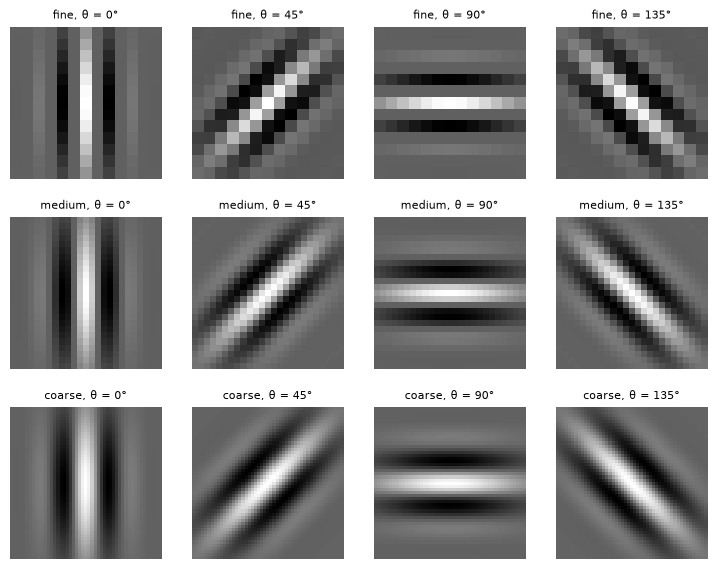

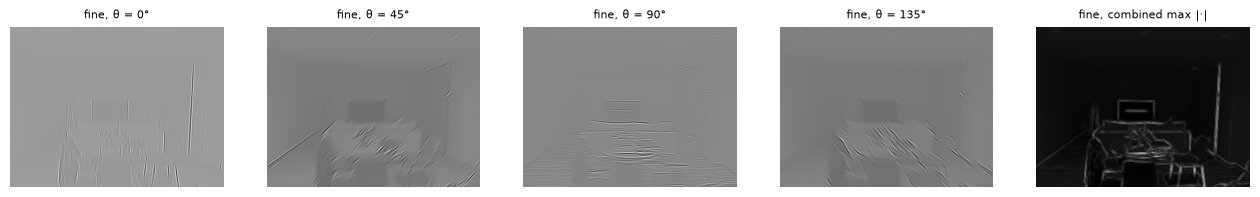

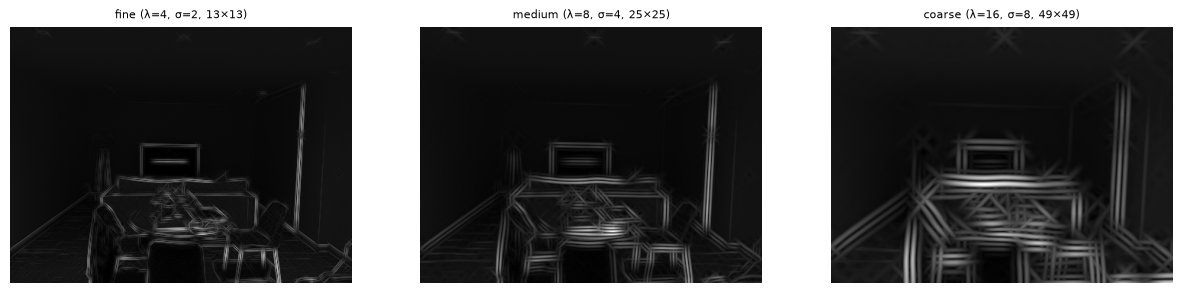

In [20]:
SETS = {"fine": SET_1, "medium": SET_2, "coarse": SET_3}

# Figure 4a: the kernels, 3 sets × 4 orientations
kernels, titles = [], []
for name, P in SETS.items():
    for th in THETAS:
        kernels.append(gab.gabor_kernel(theta=th, **P))
        titles.append(f"{name}, θ = {np.rad2deg(th):.0f}°")
fig = im.show_images(kernels, titles, cols=4, figsize=(9, 7))
fig.savefig(FIG_DIR / "fig4a_kernels.png", dpi=200, bbox_inches="tight"); plt.show()

# Figure 4b: the 4 signed responses of the fine set, and their combination
R1 = gab.gabor_bank(GRAY, SET_1, THETAS)
fig = im.show_images(list(R1) + [im.to_uint8(GABOR_MAX_1_ABS)],
                     [f"fine, θ = {d}°" for d in (0, 45, 90, 135)] + ["fine, combined max |·|"],
                     cols=5, figsize=(16, 2.8))
fig.savefig(FIG_DIR / "fig4b_set1.png", dpi=200, bbox_inches="tight"); plt.show()

# Figure 4c: the 3 combined images side by side
fig = im.show_images([im.to_uint8(GABOR_MAX_1_ABS), im.to_uint8(GABOR_MAX_2_ABS), im.to_uint8(GABOR_MAX_3_ABS)],
                     ["fine (λ=4, σ=2, 13×13)", "medium (λ=8, σ=4, 25×25)", "coarse (λ=16, σ=8, 49×49)"],
                     cols=3, figsize=(15, 4))
fig.savefig(FIG_DIR / "fig4c_sets.png", dpi=200, bbox_inches="tight"); plt.show()

GABOR_MAX = GABOR_MAX_1_ABS        # kept for Part 5 (comparison with Canny)

**Exercise 4 — for the report.** Guide for your text: for each set, (1) the question it answers and its parameters, (2) which objects or regions of your scene it highlights and which it misses, (3) *why*, in terms of T4.2 and T4.4. Then one sentence on signed versus absolute (Q4.1).

A Gabor kernel is a cosine wave inside a Gaussian window: it responds strongly where the image looks like its stripes, with the same width and orientation. We filtered the grey version of the scene (values divided by 255, so all results are on a 0--1 scale) in floating point, because the responses are signed.

Main lines of code (module `a1_gabor.py` and its use):
```python
def gabor_kernel(ksize, sigma, theta, lambd, gamma, psi=0.0):
    return cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, psi, ktype=cv2.CV_32F)

def gabor_bank(gray, params, thetas):
    for theta in thetas:
        kernel = gabor_kernel(**params, theta=theta)
        resp = cv2.filter2D(gray, cv2.CV_32F, kernel)
        responses.append(resp)

def combine_max(responses):
    resp = np.stack(responses, axis=0)
    return resp.max(axis=0).astype(np.float32)

THETAS = np.deg2rad([0, 45, 90, 135])
GABOR_MAX_1_abs = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_1, THETAS)))
```

**Orientations.** $\theta$ is the direction across the stripes, so $\theta = 0^\circ$ has vertical stripes and responds to vertical structures (the lamp legs, the chair legs, the corner of the room), and $\theta = 90^\circ$ responds to horizontal ones (the top of the sofa, the edges of the TV and the table). Turning a kernel by $180^\circ$ gives the same kernel, so the four orientations $0^\circ$, $45^\circ$, $90^\circ$ and $135^\circ$ cover all directions.

**Combination.** A dark structure on a light background, such as the lamp legs, gives a large *negative* response. With the maximum of the signed responses it disappears, and the background, whose response is about 0, is mapped to a mid grey, so the combined image looks lighter and washed out. We therefore combine the four orientations with the maximum of the absolute values: every oriented structure, bright or dark, stands out on a black background.

**Three parameter sets.** We changed only the scale, the wavelength $\lambda$ and the window width $\sigma$ (with ksize $\approx 6\sigma$), keeping $\gamma = 0.5$ and $\psi = 0$:
- **fine** ($\lambda = 4$, $\sigma = 2$): thin, precise outlines, such as the lamp legs, the chair legs, the TV frame and the edges of the table.
- **medium** ($\lambda = 8$, $\sigma = 4$): the same objects with thicker, doubled lines, and the thinnest detail is lost.
- **coarse** ($\lambda = 16$, $\sigma = 8$): only the large shapes (the sofa, the table, the TV), drawn as wide bands of parallel lines, and the thin legs disappear.
The larger the wavelength, the wider the structures the filter responds to.

---
# Part 5 — Exercise 5: the Canny edge detector, compared with Gabor (4 points)

> *Statement.* Apply the Canny Edge detector. Show the result and compare to the result from the Gabor.

> 📖 **Read before you start this part** (60 min)
> - **F&P §5.1** *Computing the Image Gradient* (§5.1.1 *Derivative of Gaussian Filters*) and **§5.2.1** *Gradient-Based Edge Detectors*. Look for: why smoothing comes before differentiating, non-maximum suppression, and linking edge points with two thresholds.
> - **[Sz §7.2, p. 455](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=481>)** *Edges and contours* ([§7.2.1, p. 456](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=482>)). Look for: the Canny pipeline and the role of the smoothing scale.
> - J. Canny, "A Computational Approach to Edge Detection", *IEEE Trans. PAMI* 8(6):679–698, 1986, Section I (the three criteria).
> - OpenCV docs: [`Canny`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html), [`GaussianBlur`, `Sobel`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html). On each OpenCV page, press Ctrl+F and type the function name to jump to it.

## Theory, step by step

### 1. An edge is a large gradient

An edge is where intensity changes quickly: an object's boundary, a shadow, a fold. "Quickly" means a large **gradient** $\nabla I = (I_x, I_y)$, with magnitude $\|\nabla I\|$ and a direction perpendicular to the edge. The **Sobel** filters estimate $I_x$ and $I_y$ with $3\times3$ kernels (they are template filters like those of Part 4, Example 4.1).

**How a 3×3 filter works, in numbers.** For each pixel, take its $3\times3$ neighbourhood, multiply it element by element with the kernel, and add the 9 products. The sum becomes the new value of that pixel. The Sobel kernel for $I_x$ is

```
-1  0  +1
-2  0  +2
-1  0  +1
```

Negative on the left, positive on the right: a flat area gives 0, dark-to-light (left to right) gives a large positive number, light-to-dark a large negative one. The kernel for $I_y$ is the same turned by 90° (negative on top, positive below). Example 5.1a does this first with printed numbers, Example 5.1b then shows the same on an image.

### ▶️ Example 5.1a — Sobel in numbers

**What this example shows:** (1) a tiny image with a sharp step of 200, (2) the kernel applied by hand on one pixel, (3) the same done by OpenCV on every pixel, (4) one row of a soft step, (5) a small bright square with $I_x$, $I_y$ and the magnitude $\sqrt{I_x^2 + I_y^2}$.


In [21]:
np.set_printoptions(linewidth=120)
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
print("Sobel kernel for I_x:\n", sobel_x)

# (1) a sharp vertical step: 0 on the left, 200 on the right
toy_step = np.zeros((5, 8), np.uint8)
toy_step[:, 4:] = 200
print("\n(1) image, a sharp step of 200:\n", toy_step)

# (2) the kernel on ONE pixel, by hand: y = 2, x = 3 (the last 0 before the jump)
toy_patch = toy_step[1:4, 2:5].astype(int)            # rows 1..3, columns 2..4
print("\n(2) 3x3 patch around (y=2, x=3):\n", toy_patch)
print("patch * kernel, element by element:\n", toy_patch * sobel_x)
print("sum =", (toy_patch * sobel_x).sum())

# (3) the same sum at every pixel, done by OpenCV
toy_gx = cv2.Sobel(toy_step, cv2.CV_32F, 1, 0, ksize=3)
print("\n(3) cv2.Sobel, I_x of the whole image:\n", toy_gx.astype(int))

# (4) a soft step: the brightness climbs over 3 pixels, like a real (slightly blurred) edge
toy_soft = np.tile(np.array([0, 0, 20, 100, 180, 200, 200, 200], np.uint8), (5, 1))
toy_gx_soft = cv2.Sobel(toy_soft, cv2.CV_32F, 1, 0, ksize=3)
print("\n(4) one row of a soft step :", toy_soft[2])
print("    its I_x                :", toy_gx_soft[2].astype(int))

# (5) a bright square: I_x, I_y and the magnitude
toy_sq = np.zeros((8, 8), np.uint8)
toy_sq[2:6, 2:6] = 200
toy_sq_gx = cv2.Sobel(toy_sq, cv2.CV_32F, 1, 0, ksize=3)
toy_sq_gy = cv2.Sobel(toy_sq, cv2.CV_32F, 0, 1, ksize=3)
toy_sq_mag = np.sqrt(toy_sq_gx ** 2 + toy_sq_gy ** 2)
print("\n(5) image, a bright square:\n", toy_sq)
print("I_x (left and right sides):\n", toy_sq_gx.astype(int))
print("I_y (top and bottom sides):\n", toy_sq_gy.astype(int))
print("magnitude sqrt(I_x^2 + I_y^2):\n", toy_sq_mag.round().astype(int))


Sobel kernel for I_x:
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

(1) image, a sharp step of 200:
 [[  0   0   0   0 200 200 200 200]
 [  0   0   0   0 200 200 200 200]
 [  0   0   0   0 200 200 200 200]
 [  0   0   0   0 200 200 200 200]
 [  0   0   0   0 200 200 200 200]]

(2) 3x3 patch around (y=2, x=3):
 [[  0   0 200]
 [  0   0 200]
 [  0   0 200]]
patch * kernel, element by element:
 [[  0   0 200]
 [  0   0 400]
 [  0   0 200]]
sum = 800

(3) cv2.Sobel, I_x of the whole image:
 [[  0   0   0 800 800   0   0   0]
 [  0   0   0 800 800   0   0   0]
 [  0   0   0 800 800   0   0   0]
 [  0   0   0 800 800   0   0   0]
 [  0   0   0 800 800   0   0   0]]

(4) one row of a soft step : [  0   0  20 100 180 200 200 200]
    its I_x                : [  0  80 400 640 400  80   0   0]

(5) image, a bright square:
 [[  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0 200 200 200 200   0   0]
 [  0   0 200 200 200 200   0   0]
 [  0   0 200 200 200 200   0   0]
 [  0  

**What to notice:**
- (2) Only the right column of the patch holds 200, so only the weights $+1, +2, +1$ count: $200 + 400 + 200$.
- (3) The step lights up **two** columns, the last dark one and the first bright one, because the kernel sees both sides of the jump from either of them.
- (4) Read the $I_x$ row from left to right across the soft edge: it rises, peaks and falls.
- (5) $I_x$ is non-zero on the left and right sides (positive where it gets brighter going right, negative where it gets darker), $I_y$ on the top and bottom. In the corners both are non-zero, so the magnitude there can exceed the value on a straight side.

### ▶️ Example 5.1b — the same on an image: a disk

**What this example shows:** a bigger toy, a disk of grey 200 (radius 30) on black, so the step of 200 now goes all around a curve. The same four quantities, displayed as images: red = positive, blue = negative (as in Part 4), and for the direction, one colour per angle. It also prints the magnitudes along row 50, which crosses the left border of the disk.


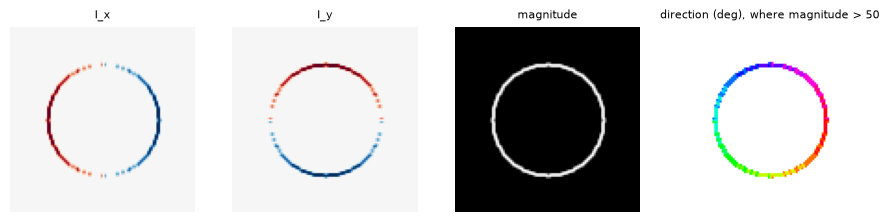

max magnitude: 894.4 for a step of 200 grey levels
width of the ring along row 50 (pixels with magnitude > 100): 6
row 50, columns 15 to 24 (left border of the disk): [  0   0   0   0 400 800 400   0   0   0]


In [22]:
toy_disk = np.zeros((100, 100), np.uint8)
cv2.circle(toy_disk, (50, 50), 30, 200, -1)                  # filled disk, grey 200
toy_gx = cv2.Sobel(toy_disk, cv2.CV_32F, 1, 0, ksize=3)      # dI/dx
toy_gy = cv2.Sobel(toy_disk, cv2.CV_32F, 0, 1, ksize=3)      # dI/dy
toy_mag = np.sqrt(toy_gx ** 2 + toy_gy ** 2)
toy_dir = np.degrees(np.arctan2(toy_gy, toy_gx))

fig, axs = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, arr, t, cm in zip(axs, [toy_gx, toy_gy, toy_mag, np.where(toy_mag > 50, toy_dir, np.nan)],
                          ["I_x", "I_y", "magnitude", "direction (deg), where magnitude > 50"],
                          ["RdBu_r", "RdBu_r", "gray", "hsv"]):
    ax.imshow(arr, cmap=cm); ax.set_title(t, fontsize=8); ax.axis("off")
plt.show()
print("max magnitude:", toy_mag.max().round(1), "for a step of 200 grey levels")
print("width of the ring along row 50 (pixels with magnitude > 100):", int((toy_mag[50] > 100).sum()))
print("row 50, columns 15 to 24 (left border of the disk):", toy_mag[50, 15:25].round().astype(int))

### 🧭 Think T5.1
> (a) In 5.1a, a step of 200 gives a magnitude of 800 on a straight side and 849 in a corner. On the disk (5.1b) the largest magnitude is about 900. If Canny compares the gradient magnitude with two thresholds, are those thresholds limited to 0–255?
> (b) In 5.1a (4) and along row 50 of the disk, the magnitude rises, peaks and falls as you cross the edge, so the edge is marked by several pixels. A good edge detector should mark *one* pixel per edge. What simple rule, applied along the gradient direction (across the edge), would keep only one?


(a) No. The gradient magnitude is a weighted sum of differences, not a grey level. A step of 200 gives 800 on a straight side and about 900 on the disk. Canny’s thresholds are on that same scale, so they can be well above 255.
(b) Keep a pixel only if its gradient magnitude is larger than both of its neighbours along the gradient direction (across the edge). Example: 80 400 640 400 80 → only 640 is kept. This is non-maximum suppression, and it makes Canny’s edges one pixel wide.

### 2. Derivatives and noise

Real images contain noise: small random variations from pixel to pixel. Example 5.2a looks at what a derivative does to it with a few printed numbers, Example 5.2b with a longer signal as plots. A derivative here is simply the **difference between neighbours**, `np.diff(a)` = `a[1:] - a[:-1]`. Smoothing with the tiny Gaussian $[1, 2, 1]/4$ replaces each value by a weighted average of itself (weight 2) and its two neighbours (weight 1 each).

### ▶️ Example 5.2a — numbers first

**What this example shows:** a step of 50 over 10 values, with noise of about ±2, its differences, then the same after the tiny blur $[1, 2, 1]/4$.


In [23]:
# a step of 50 with a little noise (each value wobbles by about 2)
toy_row = np.array([10, 13, 9, 12, 10, 60, 58, 61, 59, 62], float)
print("signal              :", toy_row.astype(int))
print("difference (no blur):", np.diff(toy_row).astype(int))

# the tiny Gaussian [1 2 1] / 4: each value becomes a weighted average with its two neighbours
toy_g = np.array([1, 2, 1]) / 4
toy_smooth = np.convolve(np.pad(toy_row, 1, mode="edge"), toy_g, mode="valid")   # pad: no border artefact
print("\nsmoothed            :", toy_smooth.round(1))
print("difference (blur)   :", np.diff(toy_smooth).round(1))


signal              : [10 13  9 12 10 60 58 61 59 62]
difference (no blur): [ 3 -4  3 -2 50 -2  3 -2  3]

smoothed            : [10.8 11.2 10.8 10.8 23.  47.  59.2 59.8 60.2 61.2]
difference (blur)   : [ 0.5 -0.5  0.  12.2 24.  12.2  0.5  0.5  1. ]


In [24]:
row = GRAY[100, 50:62].astype(int)        # 12 pixels of one row of YOUR image (astype(int): uint8 cannot go negative)
print("pixels          :", row)
print("difference      :", np.diff(row))  # next - current

row_b = cv2.GaussianBlur(GRAY, (5, 5), 1.4)[100, 50:62].astype(int)   # same pixels, image blurred first
print("pixels, blurred :", row_b)
print("difference      :", np.diff(row_b))

pixels          : [137 136 135 134 134 133 132 132 131 130 129 128]
difference      : [-1 -1 -1  0 -1 -1  0 -1 -1 -1 -1]
pixels, blurred : [137 136 135 134 134 133 132 131 131 130 129 128]
difference      : [-1 -1 -1  0 -1 -1 -1  0 -1 -1 -1]


**What to notice:** compare the two difference rows. Look at the size of the small values (the noise) and at the step's value (height, and how many positions it spreads over).

### ▶️ Example 5.2b — the same with a longer signal, as plots

**What this example shows:** a noisy step signal of 200 values, its finite difference, and the same after smoothing with a Gaussian of two different widths ($\sigma = 2$ and $\sigma = 8$). Each title prints the step's peak and the spread of the noise.


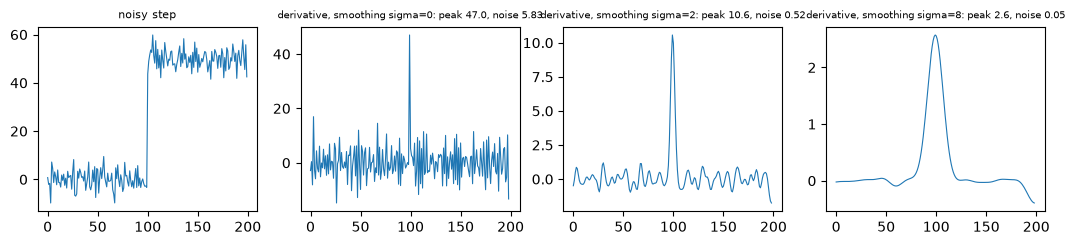

In [25]:
toy_rng = np.random.default_rng(2)
toy_sig = np.r_[np.zeros(100), np.ones(100)] * 50 + toy_rng.normal(0, 4, 200)      # a step of 50 + noise

def toy_gauss1d(s):
    x = np.arange(-4 * s, 4 * s + 1)
    g = np.exp(-x ** 2 / (2 * s ** 2))
    return g / g.sum()

fig, axs = plt.subplots(1, 4, figsize=(13, 2.4), sharex=True)
axs[0].plot(toy_sig, lw=0.8); axs[0].set_title("noisy step", fontsize=8)
for ax, s in zip(axs[1:], [0, 2, 8]):
    sm = toy_sig if s == 0 else np.convolve(np.pad(toy_sig, 4 * s, mode="edge"), toy_gauss1d(s), mode="valid")   # pad: no border artefact
    d = np.diff(sm)
    ax.plot(d, lw=0.8); ax.set_title(f"derivative, smoothing sigma={s}: peak {d[95:105].max():.1f}, noise {d[20:80].std():.2f}", fontsize=7)
plt.show()

### 🧭 Think T5.2
> (a) Without smoothing, how does the step's peak compare with the peaks produced by the noise alone? Why does differentiating make noise *worse* (think of what a difference of two neighbouring noisy values looks like)?
> (b) From $\sigma = 2$ to $\sigma = 8$: what happens to the noise, and what happens to the peak (height and width)? So what do you lose by smoothing too much, in an image with two edges close to each other?

(a) Without smoothing, the noise produces many small peaks in the derivative (up to −4 for noise of about ±2), next to the step’s peak of 50. A difference subtracts two noisy values: when one is too high and the next too low, their errors add up, so differentiating amplifies the noise.
(b) Smoothing removes most of the noise (differences drop to about 0.5), but the step’s peak gets lower and wider (50 → 12, 24, 12). With σ = 8 this goes further. Two edges close together (the two sides of a thin cable) would merge into one bump. So too much smoothing costs localisation and small details.

### 3. The Canny pipeline and OpenCV's version

Canny (1986) asked for good *detection*, good *localisation* and a *single response* per edge, and derived four steps:

1. smooth with a Gaussian of scale $\sigma$ (T5.2),
2. compute the gradient (Sobel, T5.1),
3. non-maximum suppression (T5.1 b),
4. **hysteresis thresholding** with two thresholds: pixels above `high` are certain edges, below `low` are discarded, in between they are kept *only if connected* to a certain edge.

`cv2.Canny(image, threshold1, threshold2, apertureSize=3, L2gradient=False)` requires an **8-bit** image and performs steps 2 to 4 (the smaller threshold is used for linking, the larger for the strong seeds). `L2gradient=True` uses $\sqrt{I_x^2 + I_y^2}$, the default the cheaper $|I_x| + |I_y|$. The Sobel aperture smooths only a tiny bit: step 1, with the $\sigma$ you choose, is up to you, with `cv2.GaussianBlur(src, (k, k), sigma)` (an odd `k` of about $6\sigma$, as in T4.3).

### ▶️ Example 5.3a — hysteresis in numbers

**What this example shows:** the gradient magnitude along a line of 13 pixels: a contour that starts strong and fades (positions 0 to 7), then nothing, then one isolated noise blip (position 10). First one single threshold (200, then 60), then the two thresholds of hysteresis, `low = 60` and `high = 200`, pixel by pixel.


In [26]:
# gradient magnitude along a line of pixels:
# a contour that starts strong and fades (positions 0-7), then empty, then one isolated noise blip (position 10)
toy_line = np.array([300, 250, 180, 120, 90, 70, 40, 20, 0, 0, 90, 0, 0])
low, high = 60, 200

print("one threshold at 200:", (toy_line >= 200).astype(int))
print("one threshold at 60 :", (toy_line >= 60).astype(int))

strong = toy_line >= high                    # certain edges
weak = (toy_line >= low) & ~strong           # maybe: kept only if they touch a kept pixel
kept = strong.copy()
changed = True
while changed:                               # grow from the strong pixels through neighbouring weak ones
    changed = False
    for i in np.where(weak & ~kept)[0]:
        if (i > 0 and kept[i - 1]) or (i < len(kept) - 1 and kept[i + 1]):
            kept[i] = changed = True

print(f"\nhysteresis, low={low}, high={high}:")
print(f"{'pos':>4} {'magnitude':>10} {'class':>8} {'kept':>5}")
for i, m in enumerate(toy_line):
    c = "strong" if strong[i] else "weak" if weak[i] else "-"
    print(f"{i:>4} {m:>10} {c:>8} {'yes' if kept[i] else '':>5}")


one threshold at 200: [1 1 0 0 0 0 0 0 0 0 0 0 0]
one threshold at 60 : [1 1 1 1 1 1 0 0 0 0 1 0 0]

hysteresis, low=60, high=200:
 pos  magnitude    class  kept
   0        300   strong   yes
   1        250   strong   yes
   2        180     weak   yes
   3        120     weak   yes
   4         90     weak   yes
   5         70     weak   yes
   6         40        -      
   7         20        -      
   8          0        -      
   9          0        -      
  10         90     weak      
  11          0        -      
  12          0        -      


**What to notice:** with one threshold you must choose between a contour cut short and a contour that comes with the noise. Look at positions 4 and 10 in the last table: same magnitude, different fate. (In 2-D, "touching" means any of the 8 neighbours, and Canny runs this on the edges already thinned in step 3.)

### ▶️ Example 5.3b — hysteresis on an image: a contour that fades

**What this example shows:** a toy disk whose contrast with the background fades from strong (right) to almost nothing (left). The disk was drawn already smooth, so no blur is needed here. Four threshold pairs, run with `cv2.Canny`.


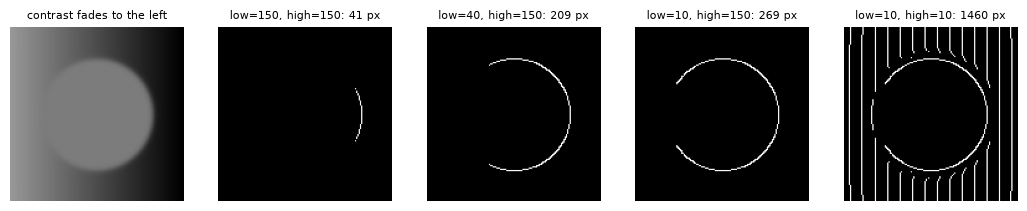

In [27]:
toy_yy, toy_xx = np.mgrid[0:140, 0:140]
toy_r = np.sqrt((toy_xx - 70) ** 2 + (toy_yy - 70) ** 2)
toy_bg = np.clip(125 - 1.1 * (toy_xx - 25), 0, 255)                   # background lighter to the left
toy_inside = 1 / (1 + np.exp((toy_r - 45) / 1.2))                     # soft disk edge, already smooth
toy_fade = (toy_inside * 125 + (1 - toy_inside) * toy_bg).astype(np.uint8)
toy_pairs = [(150, 150), (40, 150), (10, 150), (10, 10)]        # low, high thresholds for Canny
fig, axs = plt.subplots(1, len(toy_pairs)+1, figsize=(13, 2.8))
axs[0].imshow(toy_fade, cmap="gray", vmin=0, vmax=255); axs[0].set_title("contrast fades to the left", fontsize=8)
for ax, (lo, hi) in zip(axs[1:], toy_pairs):
    toy_e = cv2.Canny(toy_fade, lo, hi, L2gradient=True)
    ax.imshow(toy_e, cmap="gray"); ax.set_title(f"low={lo}, high={hi}: {int((toy_e > 0).sum())} px", fontsize=8)
for ax in axs: ax.axis("off")
plt.show()

### 🧭 Think T5.3
> (a) In 5.3b, with `low = high = 150` (one single threshold), which part of the contour is found?
> (b) Keep `high = 150` and lower `low` to 40, then 10. What changes? So what does `high` decide, and what does `low` decide?
> (c) With `low = high = 10`, what else comes in, and why?
> (d) On your scene a contour comes out broken into pieces. Which threshold do you change, and in which direction?
> (e) In 5.3a, positions 4 and 10 both have magnitude 90. Why is one kept and the other not?


(a) With low = high = 150, only the strong part of the contour (right side) is found. Elsewhere the magnitude never reaches 150.
(b) Lowering low to 40, then 10 (high fixed) follows the contour further into its faint part. high decides which edges start (the strong seeds), low decides how far they continue.
(c) With low = high = 10, the background shading also appears as vertical lines. Its small grey-level steps (whole numbers) give magnitudes above 10, and with one single low threshold every weak response is accepted, connected or not.
(d) Lower low and keep high. The weak gaps between the pieces then pass and link them to the strong parts. Lowering high would add new seeds from noise and texture.
(e) Position 4 is weak but connected through 3 and 2 to the strong pixel 1, so it is kept. Position 10 is weak and isolated, so it is dropped. Hysteresis judges a weak pixel by its connection, not by its value.

### 4. Starting thresholds and robust statistics

A common heuristic (not from Canny's paper) anchors the two thresholds on the **median** grey level $m$ of the image: `low = int(max(0, (1 - s) m))` and `high = int(min(255, (1 + s) m))`, with $s \approx 0.33$. It is only a starting point: you then tune by eye (T5.3). Canny himself recommended a high/low ratio between 2:1 and 3:1.

### ▶️ Example 5.4 — Median and percentiles

**What this example shows:** robust statistics on a toy array of exam marks, with two absurd outliers.

In [28]:
toy_marks = np.array([6.5, 7.0, 5.5, 8.0, 6.0, 7.5, 99.0, -50.0, 6.8])
print("mean   :", toy_marks.mean().round(2))
print("median :", np.median(toy_marks))
print("25th / 75th percentiles:", np.percentile(toy_marks, [25, 75]))

mean   : 10.7
median : 6.8
25th / 75th percentiles: [6.  7.5]


**What to notice:** two absurd values drag the mean far away, the median does not move. `np.median` and `np.percentile` work the same way on an image (all its pixels).

### 5. Painting a mask on an image

The comparison figure overlays Canny's edges on another image. NumPy **boolean indexing** selects the pixels where a mask is true.

### ▶️ Example 5.5 — Boolean masks on a toy array

**What this example shows:** selecting, counting and changing the elements of a 2-D array where a condition holds.

In [29]:
toy_grid = np.arange(12).reshape(3, 4)
toy_mask = toy_grid % 3 == 0
print(toy_grid, "\nmask:\n", toy_mask)
print("selected values:", toy_grid[toy_mask], "| how many:", toy_mask.sum())
toy_changed = toy_grid.copy()
toy_changed[toy_mask] = -1
print("after toy_changed[mask] = -1:\n", toy_changed, "\noriginal unchanged:", toy_grid[0, 0])
toy_rgbish = np.zeros((3, 4, 3), np.uint8)
print("shape of a 3-channel array indexed by a 2-D mask:", toy_rgbish[toy_mask].shape)
toy_rgbish[toy_mask] = (0, 0, 255)
print(toy_rgbish[toy_mask])

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
mask:
 [[ True False False  True]
 [False False  True False]
 [False  True False False]]
selected values: [0 3 6 9] | how many: 4
after toy_changed[mask] = -1:
 [[-1  1  2 -1]
 [ 4  5 -1  7]
 [ 8 -1 10 11]] 
original unchanged: 0
shape of a 3-channel array indexed by a 2-D mask: (4, 3)
[[  0   0 255]
 [  0   0 255]
 [  0   0 255]
 [  0   0 255]]


### 🧭 Think T5.4
> `toy_rgbish[toy_mask]` has shape `(4, 3)`: what do the 4 and the 3 stand for? So, to paint all the masked pixels of a colour image in one colour, what kind of object can you assign to `img[mask]` (try it on `toy_rgbish`)? Why must `overlay_edges` work on a copy (look at the last line of Example 5.5)? And if the input image is grey (2-D), what must happen before you can paint a colour on it?

4 = the number of selected pixels (the True positions of the mask), 3 = their channels (B, G, R). A 3-value tuple is copied to every selected pixel, so img[mask] = (b, g, r) paints them all in one line. overlay_edges must work on a copy, because the function receives the caller’s own array, and painting on it would change that image everywhere it’s used later. A grey image has one value per pixel and no channel axis, so it must first be converted to 3 channels (cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR), 120 → [120, 120, 120]) before a colour can be painted on it.

### 6. What a comparison of Canny and Gabor should look at

Canny and your Gabor bank both start from linear filters, but they answer different questions. Below are the axes along which to compare them. **Fill in the table yourself** in the markdown cell under it, first as a prediction from the theory (T4.2–T4.6, T5.1–T5.3), then corrected after looking at your results in *Use it*.

| Axis | Canny (prediction → observed) | Gabor bank + max (prediction → observed) |
| --- | --- | --- |
| Kind of output (values, type) | binary map, 0 / 255 (edge or not) → | continuous response, how strongly the template matches → |
| Width of what is marked | 1 pixel (non-maximum suppression) → | a band several pixels wide → |
| Orientation: used? returned? | direction computed and used inside for non-maximum suppression, no orientation preferred, not returned → | each filter is tuned to one of 4 angles, the winning angle is recoverable with argmax → |
| Scale: what sets it? | σ of the Gaussian blur (step 1) → | λ and σ of the stripes (fine / medium / coarse set) → |
| Flat regions | nothing → | a small non-zero glow, the kernel weights do not sum to 0 (0.3 for the fine set) → |
| Textured regions | many short broken edges, or almost nothing, depending on the thresholds → | strong, dense response over the whole area → |
| Contrast polarity (dark-on-light vs light-on-dark) | both (magnitude removes the sign) → | both (abs removes the sign) → |

### ❓ Question Q5.1
> In a textured region of your scene (keyboard, fabric, leaves, a bookshelf), which method will respond more, and why, in terms of what each one is built to detect? Is that a defect of one of them? *(Where to read: F&P §6.1.)*

Gabor responds more. A texture is a small pattern repeated at a regular spacing and angle, which is exactly what a Gabor template (stripes with an angle and a spacing) is built to match, so the whole area lights up. Canny is built to find individual borders, so it sees many tiny separate edges (short broken lines with low thresholds, almost nothing with high ones). Neither is a defect: Gabor describes patterns, Canny locates outlines.

## ✍️ Your task 5 — `a1_canny.py`

**Why.** One call that always smooths before Canny with an explicit scale, one that proposes thresholds to start tuning from, one that builds the overlay figure of the comparison.

**The contract**

```python
def canny_edges(gray, low, high, blur_ksize=5, blur_sigma=1.4, l2=True) -> np.ndarray   # (H, W) uint8, 0 / 255
def auto_thresholds(gray, s=0.33) -> tuple[int, int]                                     # (low, high)
def overlay_edges(img, edges, color=(0, 0, 255)) -> np.ndarray                           # (H, W, 3) uint8 BGR
```

**Requirements**

- `canny_edges`: implements the four steps of section 3 for an 8-bit grey image, with the smoothing scale given by `blur_ksize` and `blur_sigma`. `blur_ksize = 0` means "no smoothing" (useful to show its effect). `l2` selects the gradient norm.
- `auto_thresholds`: the median heuristic of section 4, exactly as written there.
- `overlay_edges`: returns a new colour image (T5.4): the input image (grey or BGR) with `color` wherever `edges > 0`. The input must not change.

In [30]:
%%writefile helpers/a1_canny.py
"""Exercise 5 - Canny edges (with explicit Gaussian smoothing) and tools to compare them with the Gabor output."""
import numpy as np
import cv2


def canny_edges(gray, low, high, blur_ksize=5, blur_sigma=1.4, l2=True):
    """Gaussian smoothing (skipped if blur_ksize == 0), then Canny.

    gray       -- (H, W) uint8
    low, high  -- hysteresis thresholds on the gradient magnitude
    blur_ksize -- odd kernel size of the Gaussian smoothing, 0 = no smoothing
    blur_sigma -- standard deviation of the smoothing
    l2         -- True: L2 gradient magnitude
    Returns an (H, W) uint8 edge map with values 0 and 255.
    """
    assert gray.ndim == 2 and gray.dtype == np.uint8, f"gray must be 2-D uint8, got {gray.shape} {gray.dtype}"
    assert low >= 0 and high >= 0, f"thresholds must be non-negative, got {low} {high}"
    assert blur_ksize ==0 or blur_ksize % 2 == 1, f"blur_ksize must be odd or 0, got {blur_ksize}"

    if blur_ksize > 0:
        gray = cv2.GaussianBlur(gray, (blur_ksize, blur_ksize), blur_sigma)   #Must apply the blur first, otherwise the Canny edge detection will be too sensitive to noise
    return cv2.Canny(gray, low, high, L2gradient=l2)                          

def auto_thresholds(gray, s=0.33):
    """Median heuristic: low = int(max(0, (1-s) m)), high = int(min(255, (1+s) m)), m = median grey. Returns (low, high)."""

    m = np.median(gray) 
    low = int(max(0, (1 - s) * m))
    high = int(min(255, (1 + s) * m))
    return low, high


def overlay_edges(img, edges, color=(0, 0, 255)):
    """New BGR image: img (BGR, or grey converted to BGR) with `color` where edges > 0. The input is not modified."""
    if img.ndim == 2: # Gray image, convert to BGR
        img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    else:
        img_bgr = img.copy()
    
    img_bgr[edges > 0] = color  #apply the mask on the image

    return img_bgr

Overwriting helpers/a1_canny.py


### ✅ Test 5

In [31]:
import a1_canny as can

rng_t5 = np.random.default_rng(0)
sq = np.zeros((100, 100), np.float32)
sq[30:70, 30:70] = 200
noisy = np.clip(sq + rng_t5.normal(0, 20, sq.shape), 0, 255).astype(np.uint8)

E = can.canny_edges(noisy, 50, 150)
assert E.shape == (100, 100) and E.dtype == np.uint8
assert set(np.unique(E)) <= {0, 255}, "Canny output must be 0 / 255"
assert 100 <= (E > 0).sum() <= 400, f"expected about the 160-pixel perimeter, got {(E > 0).sum()} edge pixels"
assert (E[40:60, 40:60] == 0).all(), "no edges inside the flat square"

far = np.ones((100, 100), bool); far[22:78, 22:78] = False
raw = cv2.Canny(noisy, 50, 150, L2gradient=True)
assert (E[far] > 0).sum() < (raw[far] > 0).sum() / 5, "the noise survives: is the image smoothed first? (T5.2)"
assert np.array_equal(can.canny_edges(noisy, 50, 150, blur_ksize=0), raw), "blur_ksize = 0 must mean no smoothing"

assert can.auto_thresholds(np.full((10, 10), 100, np.uint8)) == (67, 133)
assert can.auto_thresholds(np.full((10, 10), 250, np.uint8))[1] == 255, "high must be capped at 255"

O = can.overlay_edges(noisy, E, color=(0, 255, 0))
assert O.shape == (100, 100, 3) and O.dtype == np.uint8, "a grey input must become a 3-channel image (T5.4)"
assert (O[E > 0] == (0, 255, 0)).all(), "edge pixels must have the colour"
assert (O[E == 0][:, 0] == noisy[E == 0]).all(), "non-edge pixels must keep the grey value"
bgr = cv2.cvtColor(noisy, cv2.COLOR_GRAY2BGR); before = bgr.copy()
can.overlay_edges(bgr, E)
assert np.array_equal(bgr, before), "overlay_edges modified its input: work on a copy (T5.4)"
print("✅ Part 5 OK")

✅ Part 5 OK


### 🛠️ Use it — Canny on your scene, and the comparison

1. Start from `can.auto_thresholds(GRAY)`. Then, guided by T5.3, try two or three other pairs and one other smoothing scale (T5.2). **Figure 5a:** the edge maps side by side, parameters in the titles. Save `figures/fig5a_canny.png`. Choose one as `CANNY`, and write down *why* that one.
2. **Figure 5b:** the scene, `GABOR_MAX` (display with `im.to_uint8`), `CANNY`, and the overlay of `CANNY` on the Gabor image. Save `figures/fig5b_compare.png`.
3. Go back to the table of section 6 and complete the *observed* half. Where your prediction was wrong, find the reason.
4. Find **two specific places** in your scene where the two methods disagree most.

auto thresholds: low=99, high=196


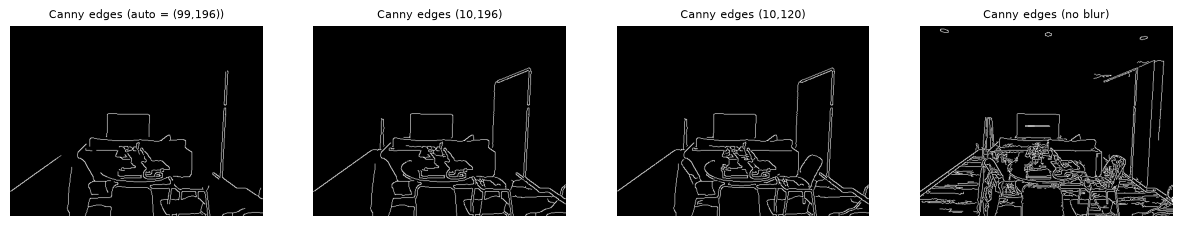

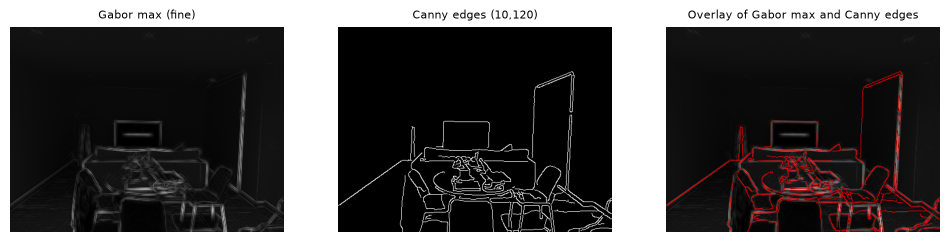

In [32]:
# TODO: thresholds (auto + your pairs), smoothing, figure 5a, CANNY = ...
# TODO: figure 5b: scene | Gabor max | Canny | overlay

import a1_canny as can
import a1_image as im
import a1_gabor as gab


low, high = can.auto_thresholds(GRAY)
print(f"auto thresholds: low={low}, high={high}")

CANNY_AUTO = can.canny_edges(GRAY, low, high, blur_ksize=5, blur_sigma=1.4)
CANNY_1 = can.canny_edges(GRAY, 10, 196, blur_ksize=5, blur_sigma=1.4)
CANNY_3 = can.canny_edges(GRAY, 10, 120, blur_ksize=5, blur_sigma=1.4)
CANNY_NO_BLUR = can.canny_edges(GRAY, 10, 120, blur_ksize=0)
CANNY_OVERLAY = can.overlay_edges(im.to_uint8(GABOR_MAX), CANNY_3, color=(0, 0, 255))

CANNY = CANNY_3  # best result for your image, to be used in the report

fig1 = im.show_images([CANNY_AUTO, CANNY_1, CANNY_3, CANNY_NO_BLUR],
               ["Canny edges (auto = (99,196))", "Canny edges (10,196)", "Canny edges (10,120)", "Canny edges (no blur)"],
               cols=4, figsize=(15, 4));
fig2 = im.show_images([GABOR_MAX, CANNY_3, CANNY_OVERLAY],
               ["Gabor max (fine)", "Canny edges (10,120)", "Overlay of Gabor max and Canny edges"],
               cols=3, figsize=(12, 4));


im.save_figure(CANNY_NO_BLUR, str(FIG_DIR / "fig5a_canny_Ksize0.png"), dpi=200)
im.save_figure(fig1, str(FIG_DIR / "fig5a_canny.png"), dpi=200)
im.save_figure(fig2, str(FIG_DIR / "fig5b_compare.png"), dpi=200)
im.save_figure(CANNY_AUTO, str(FIG_DIR / "fig5a_canny_auto.png"), dpi=200)
im.save_figure(CANNY_OVERLAY, str(FIG_DIR / "fig5a_canny_overlay.png"), dpi=200)

**Exercise 5 — for the report.** Guide for your text (5 to 8 sentences): the parameters you chose and why (T5.2, T5.3); three rows of your table, the most telling ones, each with what you observed; the two places of disagreement, each explained with the theory (T4.2–T4.6 for Gabor, T5.1–T5.3 for Canny); one sentence on what each method is good for (Q5.1).

We applied Canny to the grey scene after a Gaussian blur ($5\times5$, $\sigma = 1.4$), with the L2 gradient magnitude:
```python
if blur_ksize > 0:
    gray = cv2.GaussianBlur(gray, (blur_ksize, blur_ksize), blur_sigma)
return cv2.Canny(gray, low, high, L2gradient=l2)
CANNY = can.canny_edges(GRAY, 10, 120, blur_ksize=5, blur_sigma=1.4)
```

We started from the median heuristic, which gave (low, high) = (99, 196). With this pair the door frame on the right was broken and the floor--wall line was short (Fig. 3). Lowering low to 10 completed these contours, because hysteresis keeps weak pixels that are connected to strong ones. Lowering high to 120 also closed the round table and the chairs, while the walls and the floor stayed empty, so we kept (10, 120). Without the blur, the same pair turned the floor planks, the ceiling lights and the chair fabric into edges: the blur is what keeps texture and noise out.

Fig. 4 compares this result with the Gabor bank (fine set, maximum of the absolute responses). Canny gives a binary map of 1-pixel lines, while Gabor gives a continuous response in bands several pixels wide. Both mark dark-on-light and light-on-dark edges, Canny because it uses the gradient magnitude and Gabor because we took the absolute value. They disagree most in two places. On the door frame, Gabor shows a wide band and Canny a single thin line in its middle, because non-maximum suppression keeps only the peak across the edge. On the floor, Gabor responds to the wooden texture while Canny marks nothing, because a Gabor filter is a template of repeated stripes, while Canny looks for individual borders and the blur removes the small ones. Canny is better for locating object outlines, and Gabor for describing oriented patterns and textures.

---
# Part 6 — Exercise 6: Gaussian and Laplacian pyramids (4 points)

> *Statement.* Implement a Gaussian and a Laplacian pyramid. Show the results. Comment on the high and low frequencies and their locations in the results.

> 📖 **Read before you start this part** (60 min)
> - **F&P §4.3–4.4** *Spatial Frequency and Fourier Transforms*, *Sampling and Aliasing*. Look for: what a high and a low spatial frequency look like, and why sampling needs smoothing first.
> - **F&P §4.7** *Technique: Scale and Image Pyramids*, **§4.7.1** *The Gaussian Pyramid*.
> - **[Sz §3.5, p. 149](<../../books/Szeliski (2022) - Computer Vision Algorithms and Applications, 2nd ed.pdf#page=175>)** *Pyramids and wavelets* (interpolation, decimation, multi-resolution representations). Look for: the Laplacian pyramid figure.
> - P. Burt and E. Adelson, "The Laplacian Pyramid as a Compact Image Code", *IEEE Trans. Communications* 31(4):532–540, 1983 ([abstract and PDF](https://persci.mit.edu/pub_abstracts/pyramid83_abs.html)). Figures 1 to 4.
> - OpenCV docs: [`pyrDown`, `pyrUp`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html) (read the default output sizes), and the [image pyramids tutorial](https://docs.opencv.org/4.x/dc/dff/tutorial_py_pyramids.html). On each OpenCV page, press Ctrl+F and type the function name to jump to it.

## Theory, step by step

### 1. Spatial frequency

A *low* spatial frequency is a slow change across the image: the shading of a wall, the overall brightness of a large object. A *high* frequency is a fast change: an edge, printed letters, the weave of a fabric, noise. Every image is a mix of all of them (F&P §4.3). A blur (a Gaussian filter) is a **low-pass** filter: it removes the fast changes and keeps the slow ones.

### 🧭 Think T6.1
> Look at your scene (or imagine your desk). Name two things that are mostly low frequency and two that are mostly high frequency. After a strong Gaussian blur, which of the four would you still recognise?

Low frequency: the wall and the ceiling (smooth shading). High frequency: the wooden floor and the chair fabric (fast, repeated changes). After a strong blur, the wall and the ceiling are still recognisable, while the floor and the fabric become a smooth grey. Large objects such as the sofa survive as blurred blobs: their overall shape is low frequency, and their outlines are high frequency.

### 2. Keeping every other pixel

Halving an image's size keeps every other row and column: the sampling grid becomes twice as coarse. F&P §4.4 explains what happens to frequencies too fast for the new grid. Example 6.1 shows it in 1-D, with a blur kernel used by `pyrDown`, $[1, 4, 6, 4, 1]/16$.

### ▶️ Example 6.1 — Subsampling a fast oscillation (1-D)

**What this example shows:** a toy signal oscillating at 0.4 cycles per sample, subsampled by 2, without and with a blur first.

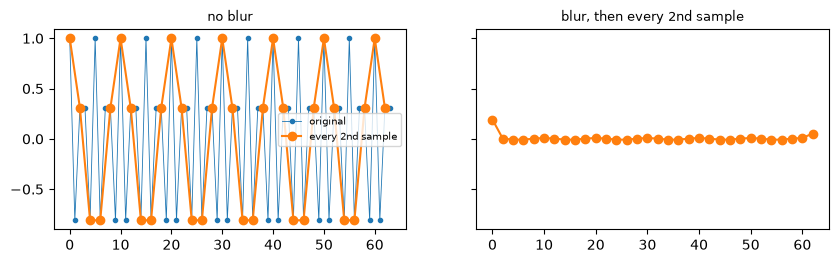

amplitude kept without blur: 1.00 | with blur: 0.01


In [33]:
toy_n = np.arange(64)
toy_sig = np.cos(2 * np.pi * 0.4 * toy_n)
toy_b5 = np.array([1, 4, 6, 4, 1]) / 16.0
toy_blurred = np.convolve(toy_sig, toy_b5, mode="same")

fig, axs = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True)
axs[0].plot(toy_n, toy_sig, ".-", lw=0.6, label="original"); axs[0].plot(toy_n[::2], toy_sig[::2], "o-", label="every 2nd sample")
axs[0].set_title("no blur", fontsize=9); axs[0].legend(fontsize=7)
axs[1].plot(toy_n[::2], toy_blurred[::2], "o-", color="C1"); axs[1].set_title("blur, then every 2nd sample", fontsize=9)
plt.show()
print("amplitude kept without blur: %.2f | with blur: %.2f" % (np.abs(toy_sig[::2]).max(), np.abs(toy_blurred[8:-8:2]).max()))

### 🧭 Think T6.2
> (a) In the left panel, the orange samples draw a wave: is it fast or slow? Was that slow wave in the original signal? What is this effect called (Part 3, T3.5)?
> (b) What did the blur do before sampling? So what is the right order of operations to halve an image, and what would the levels of a "pyramid" built without blur look like?

(a) Without blur, the samples draw a false slow wave that was not in the original signal: this is aliasing (as with INTER_NEAREST in T3.5). (b) The blur removes the frequencies that are too fast for the coarser grid, so they cannot fold into false patterns. The right order is blur first, then keep every other pixel. A pyramid built without blur would show false patterns (stripes, speckles) on fine textures, worse at every level.

### 3. The Gaussian pyramid

$G_0$ is the image. Each next level is the previous one **blurred, then subsampled by 2** (T6.2): $G_{i+1} = \mathrm{REDUCE}(G_i)$. `cv2.pyrDown` does REDUCE with the 5 × 5 kernel $\frac{1}{256}\,[1,4,6,4,1]^T[1,4,6,4,1]$, and its documentation gives the default output size: `((cols + 1) // 2, (rows + 1) // 2)` (width, height).

### 🧭 Think T6.3
> Your grey scene is 336 rows × 448 columns. Write the shapes (rows, cols) of $G_1$ to $G_4$. At which level does a size become odd for the first time, and what would `pyrDown` give at the next level? Each level is a low-pass version of the image: which of your four things of T6.1 survive until $G_4$?

G₁ = 168 × 224, G₂ = 84 × 112, G₃ = 42 × 56, G₄ = 21 × 28 (rows × cols). The rows become odd for the first time at G₄ (21), and one more pyrDown would give (21 + 1) // 2 = 11 rows. Each level is a low-pass version of the image: in G₄ the wall and the ceiling are still visible, while the floor and the fabric have lost their texture.

### 4. The Laplacian pyramid

What does $G_{i+1}$ lack compared with $G_i$? To compare them they must have the same size. **EXPAND** brings a level back to the size of the one below: insert zeros between the samples, then blur with the same kernel times 4. That is `cv2.pyrUp`. Burt and Adelson (1983) define

$$
L_i = G_i - \mathrm{EXPAND}(G_{i+1}), \qquad i = 0, \dots, N-1 .
$$

### 🧭 Think T6.4
> $G_i$ is a low-pass image keeping frequencies up to some limit $f_i$. $\mathrm{EXPAND}(G_{i+1})$ only contains what survived one more blur, frequencies up to about $f_i / 2$. Which frequencies does their difference $L_i$ contain? Is $L_i$ low-pass, high-pass, or something in between? Which kind of image regions will be close to zero in $L_i$?

$L_i$ keeps the frequencies between $f_i/2$ and $f_i$: the details that one more blur removes. It is a **band-pass** image, $L_0$ with the finest details and the higher levels with coarser ones. Smooth regions, such as the wall and the ceiling, are close to zero, because they have no detail at that scale. In the row example, $L_0$ was large at the jumps 10 ↔ 200 and 0 on a flat row.

### 🧭 Think T6.5
> (a) Rearrange the definition of $L_i$ to express $G_i$ from $L_i$ and $G_{i+1}$. Starting from the top, how do you rebuild $G_0$?
> (b) The top level $G_N$ has no level above it to subtract. What must the top of the Laplacian pyramid, $L_N$, be so that (a) works? What would be lost if you forgot it?

(a) $G_i = L_i + \mathrm{EXPAND}(G_{i+1})$. Start from the top $G_N$, expand it and add $L_{N-1}$ to get $G_{N-1}$, and repeat down to $G_0$. (b) $L_N$ must be $G_N$ itself (a copy), the blurred residual. Without it, the rebuild would only contain details around zero: the overall brightness and the large regions (walls, ceiling) would be lost.

### 5. Sizes and types when going back up

`cv2.pyrUp` doubles the size by default. Example 6.2 shows what that does with an odd size, and Example 6.3 what happens when you subtract in the wrong type.

### ▶️ Example 6.2 — Down and up with an odd size

**What this example shows:** a toy 75 × 101 array, down then up with the defaults.

In [34]:
toy_img = np.random.default_rng(1).uniform(0, 255, (75, 101)).astype(np.float32)
toy_down = cv2.pyrDown(toy_img)
toy_up = cv2.pyrUp(toy_down)
print("original", toy_img.shape, "-> pyrDown", toy_down.shape, "-> pyrUp", toy_up.shape, "| dtype kept:", toy_down.dtype)
try:
    toy_img - toy_up
except ValueError as err:
    print("subtracting:", err)

original (75, 101) -> pyrDown (38, 51) -> pyrUp (76, 102) | dtype kept: float32
subtracting: operands could not be broadcast together with shapes (75,101) (76,102) 


### 🧭 Think T6.6
> Why does the round trip not give back 75 × 101? `pyrUp` has a `dstsize` parameter (read its [documentation](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html), Ctrl+F `pyrUp`): in which order does it take the two numbers (the same convention as `resize`'s `dsize`, Part 3 T3.3), and which size will you pass when you compute $\mathrm{EXPAND}(G_{i+1})$ for $L_i$? Will your 448 × 336 scene hit this problem within four levels (T6.3)?

`pyrDown` rounded 75 up to 38 (and 101 up to 51), and `pyrUp` doubles them to 76 × 102, which no longer matches 75 × 101, so the subtraction fails. `dstsize` is (width, height), like the `dsize` of `resize`, and we pass the size of $G_i$, the level we subtract from. Our scene only becomes odd at $G_4$ (21 rows), which is never the level we subtract from, so the default would work here, but the function always passes `dstsize` so that it works for any size.

### ▶️ Example 6.3 — 10 minus 20, three ways

**What this example shows:** the same subtraction on 1 × 1 images of different types.

In [35]:
toy_a = np.array([[10]], np.uint8); toy_b = np.array([[20]], np.uint8)
print("NumPy uint8  :", toy_a - toy_b)
print("cv2.subtract :", cv2.subtract(toy_a, toy_b))
print("float32      :", toy_a.astype(np.float32) - toy_b.astype(np.float32))

NumPy uint8  : [[246]]
cv2.subtract : [[0]]
float32      : [[-10.]]


### 🧭 Think T6.7
> Which of the three answers is right, and what did the other two do? About what fraction of the values of a Laplacian level do you expect to be negative (T6.4)? So at which moment of your function must the conversion to `float32` happen?

Only float32 gives −10. NumPy `uint8` wrapped around to 246, and `cv2.subtract` saturated at 0. A Laplacian level oscillates around zero, so about half of its values are negative (49 % in our $L_0$). So $G_0$ must be converted to `float32` at the very start, before the first `pyrDown`.

### 6. Showing pyramids

### ▶️ Example 6.4 — Signed values, and rows of images of decreasing size

**What this example shows:** a toy signed array shown in grey with an offset (mid-grey = 0), then a row of toy images whose axes keep their relative sizes.

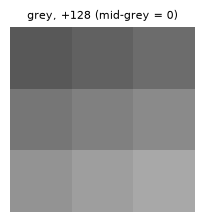

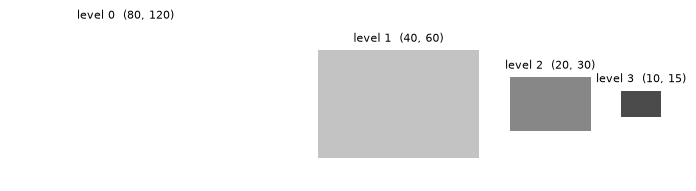

In [36]:
toy_signed = np.linspace(-40, 40, 9).reshape(3, 3).astype(np.float32)
fig, ax = plt.subplots(figsize=(2.6, 2.4))
ax.imshow(toy_signed + 128, cmap="gray", vmin=0, vmax=255); ax.set_title("grey, +128 (mid-grey = 0)", fontsize=8); ax.axis("off")
plt.show()

toy_levels = [np.full((80 // 2 ** i, 120 // 2 ** i), 255 - 60 * i, np.uint8) for i in range(4)]
toy_widths = [lv.shape[1] for lv in toy_levels]
fig, axs = plt.subplots(1, len(toy_levels), figsize=(9, 2), gridspec_kw={"width_ratios": toy_widths})
for toy_i, (ax, lv) in enumerate(zip(axs, toy_levels)):
    ax.imshow(lv, cmap="gray", vmin=0, vmax=255); ax.set_title(f"level {toy_i}  {lv.shape}", fontsize=8); ax.axis("off")
plt.show()

**What to notice:** with the offset, mid-grey means zero, lighter positive, darker negative. Zero (nothing at this scale) is the most important value to read in a Laplacian level. Use the **same** limits for all levels, or say in the caption that each is stretched separately. `width_ratios` gives each axis a width proportional to its image: the classic pyramid look.

### ❓ Question Q6.1
> Put T6.1, T6.3 and T6.4 together for *your* scene, as a prediction to check in *Use it*: which objects will be bright (large $|L_0|$) in $L_0$? Which will appear in $L_2$–$L_3$ but not in $L_0$? What will $G_4$ still show? Where will every $L_i$ be near zero?

$L_0$: the finest details, such as the floor planks, the chair fabric, the cables, the light bar of the TV and the ceiling lights. $L_2$–$L_3$: the outlines of the large objects as broad bands (sofa, table, chairs, the line between floor and wall), with the fine texture gone. $G_4$: only the layout of light regions (ceiling, walls) and dark ones (TV, chairs). Near zero in every $L_i$: the ceiling and the walls.

## ✍️ Your task 6 — `a1_pyramids.py`

**Why.** The statement says *implement*: you build both pyramids level by level from REDUCE and EXPAND, and the reconstruction proves your Laplacian pyramid is complete (T6.5).

**The contract**

```python
def gaussian_pyramid(img, levels) -> list[np.ndarray]     # levels + 1 float32 arrays: G_0 ... G_levels
def laplacian_pyramid(gauss) -> list[np.ndarray]          # same length: L_0 ... L_N
def reconstruct(lap) -> np.ndarray                         # G_0 rebuilt, float32
```

**Requirements**

- `gaussian_pyramid`: $G_0$ is the image itself converted to `float32` (T6.7), values unchanged (no division by 255).
- `laplacian_pyramid`: the definition of section 4, plus the top level of T6.5 (b) as a *copy*. Works for any size, odd ones included (T6.6). All levels `float32`.
- `reconstruct`: T6.5 (a). Must give back $G_0$ up to rounding, for any size.
- All three work for grey and for colour images (OpenCV's pyramid functions handle both).

In [37]:
%%writefile helpers/a1_pyramids.py
"""Exercise 6 - Gaussian and Laplacian pyramids (Burt & Adelson, 1983) with OpenCV's REDUCE (pyrDown) and EXPAND (pyrUp)."""
import numpy as np
import cv2

def gaussian_pyramid(img, levels):
    """[G_0, ..., G_levels]: G_0 = img as float32 (values unchanged), G_{i+1} = REDUCE(G_i). Returns a list."""
    assert levels >= 0, f"levels must be non-negative, got {levels}"

    gauss = [img.astype(np.float32)]
    for _ in range(levels):
        gauss.append(cv2.pyrDown(gauss[-1]))
    return gauss

def laplacian_pyramid(gauss):
    """[L_0, ..., L_N] from a Gaussian pyramid: L_i = G_i - EXPAND(G_{i+1}), L_N = copy of G_N.

    All levels float32 (signed). Same length as `gauss`. Works for odd sizes.
    """
    lap = []
    for i in range(len(gauss) - 1):
        h, w = gauss[i].shape[:2]
        expanded = cv2.pyrUp(gauss[i + 1], dstsize=(w, h))
        lap.append(gauss[i] - expanded)
    lap.append(gauss[-1].copy())
    return lap

def reconstruct(lap):
    """Collapse a Laplacian pyramid back to G_0 (float32)."""
    img = lap[-1].copy()
    for level in reversed(lap[:-1]):
        h, w = level.shape[:2]
        img = cv2.pyrUp(img, dstsize=(w, h)) + level
    return img

Overwriting helpers/a1_pyramids.py


### ✅ Test 6

In [38]:
import a1_pyramids as pyr

img6 = np.random.default_rng(6).uniform(0, 255, (336, 448)).astype(np.uint8)
G = pyr.gaussian_pyramid(img6, 4)
assert isinstance(G, list) and len(G) == 5, "levels = 4 gives 5 images, G_0 to G_4"
assert [g.shape for g in G] == [(336, 448), (168, 224), (84, 112), (42, 56), (21, 28)], [g.shape for g in G]
assert all(g.dtype == np.float32 for g in G), "every level must be float32 (T6.7)"
assert np.array_equal(G[0], img6.astype(np.float32)), "G_0 is the image itself, values unchanged"
assert G[1].std() < G[0].std(), "each level must be smoother (blurred) than the one below (T6.2)"

L = pyr.laplacian_pyramid(G)
assert len(L) == 5 and [l.shape for l in L] == [g.shape for g in G]
assert all(l.dtype == np.float32 for l in L)
assert L[0].min() < 0, "Laplacian levels are signed: did something clip the negatives? (T6.7)"
assert np.array_equal(L[-1], G[-1]) and L[-1] is not G[-1], "the top level must be a copy of G_N (T6.5 b)"

rec = pyr.reconstruct(L)
assert rec.shape == img6.shape and np.abs(rec - img6).max() < 1e-3, f"reconstruction error {np.abs(rec - img6).max()} (T6.5 a)"

odd = np.random.default_rng(7).uniform(0, 255, (101, 75)).astype(np.float32)
assert np.abs(pyr.reconstruct(pyr.laplacian_pyramid(pyr.gaussian_pyramid(odd, 3))) - odd).max() < 1e-3, "odd sizes: T6.6"
col = np.random.default_rng(8).uniform(0, 255, (64, 96, 3)).astype(np.uint8)
assert np.abs(pyr.reconstruct(pyr.laplacian_pyramid(pyr.gaussian_pyramid(col, 3))) - col).max() < 1e-3, "colour images too"
print("✅ Part 6 OK")

✅ Part 6 OK


### 🛠️ Use it — your pyramids, and the comment

1. Build `G` (four levels) and `L` from `GRAY`.
2. Compute the reconstruction error, `np.abs(pyr.reconstruct(L) - GRAY).max()`, and write it down: it shows the decomposition is complete.
3. **Figure 6a:** the five Gaussian levels, sizes in the titles. Save `figures/fig6a_gaussian.png`.
4. **Figure 6b:** $L_0 \dots L_3$ in grey with one shared limit (mid-grey = 0), and $L_4$ in grey. Save `figures/fig6b_laplacian.png`.
5. One number per level supports the comment: compute something that measures how much detail each $L_i$ holds (think of what "near zero everywhere" would give). Print it in a small table.
6. Compare with your prediction of Q6.1.

sizes: [(336, 448), (168, 224), (84, 112), (42, 56), (21, 28)]
reconstruction error: 7.6293945e-06


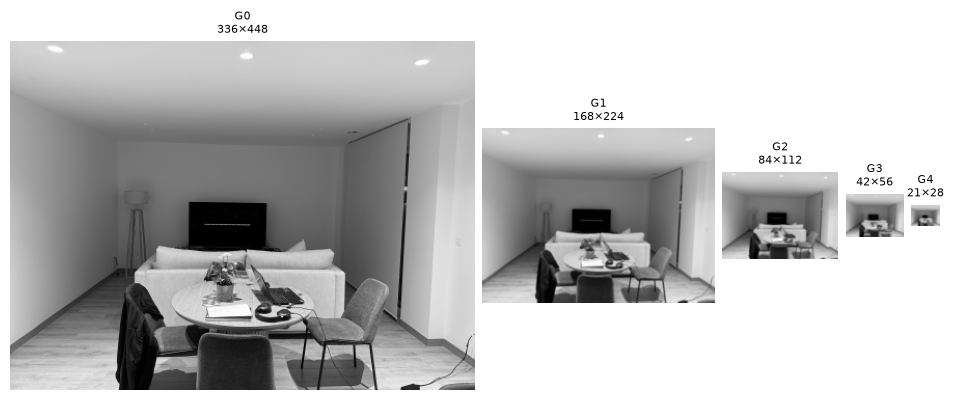

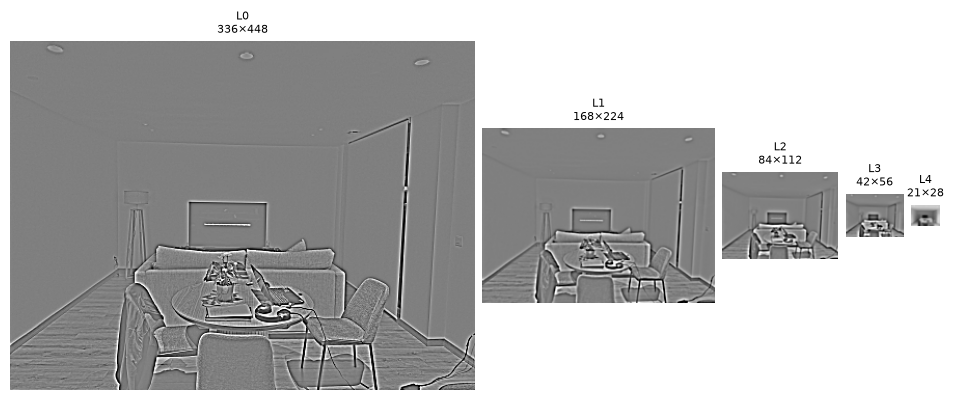

shared grey limit: ±47.6
level  size      mean |L_i|
L0     336×448     3.71
L1     168×224     4.16
L2      84×112     5.50
L3      42×56      7.72


In [39]:
import a1_image as im
import a1_pyramids as pyr

LEVELS = 4
G = pyr.gaussian_pyramid(GRAY, LEVELS)
L = pyr.laplacian_pyramid(G)

print("sizes:", [g.shape for g in G])
print("reconstruction error:", np.abs(pyr.reconstruct(L) - GRAY).max())

widths = [g.shape[1] for g in G]
fig, axs = plt.subplots(1, len(G), figsize=(12, 5), gridspec_kw={"width_ratios": widths, "wspace": 0.04})
for i, (ax, g) in enumerate(zip(axs, G)):
    ax.imshow(g, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"G{i}\n{g.shape[0]}×{g.shape[1]}", fontsize=8); ax.axis("off")
im.save_figure(fig, FIG_DIR / "fig6a_gaussian.png", dpi=200); plt.show()

lim = max(np.percentile(np.abs(l), 99) for l in L[:-1])
fig, axs = plt.subplots(1, len(L), figsize=(12, 5), gridspec_kw={"width_ratios": widths, "wspace": 0.04})
for i, (ax, l) in enumerate(zip(axs, L)):
    if i < len(L) - 1:
        ax.imshow(l, cmap="gray", vmin=-lim, vmax=lim)
    else:
        ax.imshow(l, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"L{i}\n{l.shape[0]}×{l.shape[1]}", fontsize=8); ax.axis("off")
im.save_figure(fig, FIG_DIR / "fig6b_laplacian.png", dpi=200); plt.show()

print(f"shared grey limit: ±{lim:.1f}")
print("level  size      mean |L_i|")
for i, l in enumerate(L[:-1]):
    print(f"L{i}     {l.shape[0]:>3}×{l.shape[1]:<4}  {np.abs(l).mean():6.2f}")

**Exercise 6 — for the report.** Guide for your text (5 to 8 sentences): what each pyramid keeps (low-pass, band-pass: T6.3, T6.4); *where* the high frequencies are in your scene, naming objects, and in which levels; how the content of $L_i$ moves to coarser structures as $i$ grows, with your per-level numbers; what the top level still holds; the reconstruction error and what it proves (T6.5); one place where the result differed from your prediction (Q6.1), and why.

We built both pyramids level by level with OpenCV's REDUCE (`pyrDown`: blur with $[1,4,6,4,1]/16$, then keep every other pixel) and EXPAND (`pyrUp`: back to the size of the level below), in float32 because the Laplacian levels are signed. Main lines of `a1_pyramids.py`:
```python
gauss = [img.astype(np.float32)]
for _ in range(levels):
    gauss.append(cv2.pyrDown(gauss[-1]))
for i in range(len(gauss) - 1):
    h, w = gauss[i].shape[:2]
    expanded = cv2.pyrUp(gauss[i + 1], dstsize=(w, h))
    lap.append(gauss[i] - expanded)
lap.append(gauss[-1].copy())
```

Each Gaussian level is the previous one blurred and halved, so it keeps only the lower frequencies (Fig. 5, left). The floor planks and the chair fabric disappear first, then the objects on the table, and $G_4$ ($21\times28$) only shows the layout of the light ceiling and walls against the darker TV and chairs.

Each Laplacian level, $L_i = G_i - \mathrm{EXPAND}(G_{i+1})$, keeps the band of frequencies that one more blur removes (Fig. 5, right). The high frequencies are in $L_0$: the floor planks, the chair fabric, the cables on the floor, the light bar of the TV and the ceiling lights. In $L_2$ and $L_3$ the scene only appears as broad bands around the large objects: the sofa, the table, the chairs and the line between the floor and the wall. The ceiling and the walls are close to zero at every level, because they have no detail at any scale, and their brightness is kept only by the top level, $L_4 = G_4$. Rebuilding the image from the Laplacian pyramid gives back $G_0$ with a maximum error of $8\cdot10^{-6}$ grey levels, so the decomposition loses nothing.

We expected most of the detail in $L_0$, but the mean of $|L_i|$ grows from 3.7 ($L_0$) to 4.2, 5.5 and 7.7 ($L_3$). Each value of a coarse level measures the contrast of a large structure, such as a whole chair against the floor, which is larger than the contrast of one plank against the next.